# Proyecto Final - Procesamiento Digital de Señales
**Materia**: Limpieza de voz: diseño FIR por ventanas, plano Z y contraste con IIR

**Grupo**: 03

**Equipo**: 02

### Integrantes:
* Espinoza Matamoros Percival Ulises
* Lugo Manzano Rodrigo
* García Cortés Adolfo de Jésus

## Importacion y Configuracion del Entorno

In [ ]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import scipy.io.wavfile as wavfile
import scipy.signal as sig
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Audio, HTML, Math

%matplotlib inline
plt.rcParams.update({
    "figure.figsize": (12, 4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
})

# Configuración de rutas
if os.path.exists("input"):
    INPUT_DIR, OUTPUT_DIR = "input", "output"
elif os.path.exists("../input"):
    INPUT_DIR, OUTPUT_DIR = "../input", "../output"
else:
    INPUT_DIR, OUTPUT_DIR = "input", "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Diagnóstico y FFT por ventanas

Cargar, escuchar y graficar cada WAV. Identificar la banda ocupada por la voz y las características de las
interferencias.

## 1.1 Mustreo

In [ ]:
def cargar_y_muestrear_wav(ruta):
    """
    Entrada (.wav) -> Muestreo y normalización a flotante [-1, 1].
    """
    fs, data = wavfile.read(ruta)
    if data.ndim > 1:
        data = data[:, 0]
    if np.issubdtype(data.dtype, np.integer):
        escala = float(np.iinfo(data.dtype).max) + 1.0
        x = data.astype(np.float64) / escala
    else:
        x = data.astype(np.float64)
    t = np.arange(len(x)) / float(fs)
    return fs, x, t

def exportar_wav_16bit(ruta, fs, y):
    """
    Reconstrucción / Cuantización PCM 16-bit sin saturación (clipping).
    """
    y_clean = np.nan_to_num(y, nan=0.0, posinf=0.0, neginf=0.0)
    pico = np.max(np.abs(y_clean))
    if pico > 0.99:
        y_clean = y_clean * (0.99 / pico)
    y_int16 = np.clip(np.round(y_clean * 32767.0), -32768, 32767).astype(np.int16)
    wavfile.write(ruta, int(fs), y_int16)
    return ruta

fs_a, x_a, t_a = cargar_y_muestrear_wav(os.path.join(INPUT_DIR, "PDS_voz_60Hz_4s.wav"))
fs_b, x_b, t_b = cargar_y_muestrear_wav(os.path.join(INPUT_DIR, "PDS_voz_fuente_simulada_4s.wav"))

assert fs_a == fs_b == 16000, "Se espera Fs = 16 kHz"
FS = fs_a
NYQ = FS / 2.0

print(f"Audio A: N={len(x_a)} muestras | Fs={FS} Hz | Duración={len(x_a)/FS:.2f} s | RMS={np.sqrt(np.mean(x_a**2)):.4f} | Pico={np.max(np.abs(x_a)):.4f}")
print(f"Audio B: N={len(x_b)} muestras | Fs={FS} Hz | Duración={len(x_b)/FS:.2f} s | RMS={np.sqrt(np.mean(x_b**2)):.4f} | Pico={np.max(np.abs(x_b)):.4f}")

Audio A: N=64000 muestras | Fs=16000 Hz | Duración=4.00 s | RMS=0.0598 | Pico=0.5235
Audio B: N=64000 muestras | Fs=16000 Hz | Duración=4.00 s | RMS=0.0655 | Pico=0.6162


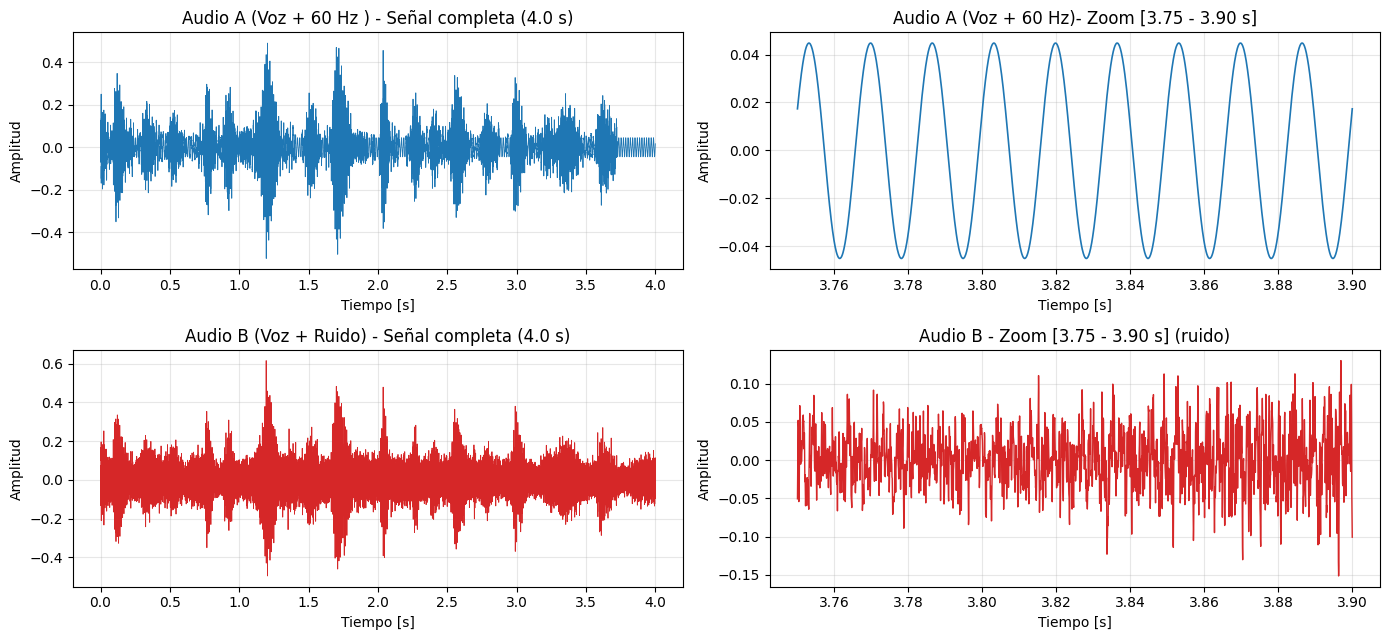

Audio A original (60 Hz):


Audio B original (Ruido):


In [ ]:
# Visualización en el dominio del tiempo)
fig, axes = plt.subplots(2, 2, figsize=(14, 6.5))

axes[0, 0].plot(t_a, x_a, color="#1f77b4", lw=0.6)
axes[0, 0].set_title("Audio A (Voz + 60 Hz ) - Señal completa (4.0 s)")
axes[0, 0].set_xlabel("Tiempo [s]"); axes[0, 0].set_ylabel("Amplitud")

mask_zoom = (t_a >= 3.75) & (t_a <= 3.90)
axes[0, 1].plot(t_a[mask_zoom], x_a[mask_zoom], color="#1f77b4", lw=1.2)
axes[0, 1].set_title("Audio A (Voz + 60 Hz)- Zoom [3.75 - 3.90 s]")
axes[0, 1].set_xlabel("Tiempo [s]"); axes[0, 1].set_ylabel("Amplitud")

axes[1, 0].plot(t_b, x_b, color="#d62728", lw=0.6)
axes[1, 0].set_title("Audio B (Voz + Ruido) - Señal completa (4.0 s)")
axes[1, 0].set_xlabel("Tiempo [s]"); axes[1, 0].set_ylabel("Amplitud")

axes[1, 1].plot(t_b[mask_zoom], x_b[mask_zoom], color="#d62728", lw=1.0)
axes[1, 1].set_title("Audio B - Zoom [3.75 - 3.90 s] (ruido)")
axes[1, 1].set_xlabel("Tiempo [s]"); axes[1, 1].set_ylabel("Amplitud")

plt.tight_layout()
plt.show()

print("Audio A original (60 Hz):")
display(Audio(x_a, rate=FS))
print("Audio B original (Ruido):")
display(Audio(x_b, rate=FS))

## 1.2  y 1.3 Ventanas y Fuga Espectral

In [ ]:
def calcular_espectros_segmentados(x, fs, N=1024, solapamiento=0.5, ventana="hann"):
    """
    Divide x[n] en segmentos de longitud N, aplicando la ventana de Hann antes de la FFT
    y devuelve frecuencias, espectros por segmento (en magnitud y dB) y espectro promedio.
    """
    paso = max(1, int(N * (1.0 - solapamiento)))
    w = sig.get_window(ventana, N, fftbins=True)
    Sw = np.sum(w)
    freqs = np.fft.rfftfreq(N, d=1.0 / fs)

    espectros_mag = []
    for inicio in range(0, len(x) - N + 1, paso):
        seg = x[inicio : inicio + N] * w
        X = np.fft.rfft(seg)
        # Escala unilateral en amplitud
        mag = (2.0 / Sw) * np.abs(X)
        mag[0] *= 0.5
        if N % 2 == 0:
            mag[-1] *= 0.5
        espectros_mag.append(mag)

    espectros_mag = np.array(espectros_mag)
    # Promedio RMS espectral para representar potencia media en dB
    mag_prom = np.sqrt(np.mean(espectros_mag**2, axis=0))
    mag_seg_db = 20.0 * np.log10(espectros_mag + 1e-12)
    mag_prom_db = 20.0 * np.log10(mag_prom + 1e-12)
    return freqs, mag_seg_db, mag_prom_db, espectros_mag

def graficar_diagnostico_fft(x, fs, titulo, N=2048, ventana="hann", f_zoom=350, max_seg_plot=40):
    freqs, seg_db, prom_db, _ = calcular_espectros_segmentados(x, fs, N=N, solapamiento=0.5, ventana=ventana)
    df = fs / N
    dt = N / fs * 1000.0

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
    idx_segs = np.linspace(0, len(seg_db) - 1, min(len(seg_db), max_seg_plot), dtype=int)

    for ax, xlim, subtitulo in [
        (ax1, (0, fs / 2), f"Espectro completo (0 - {int(fs/2)} Hz)"),
        (ax2, (0, f_zoom), f"Zoom bajas frecuencias (0 - {f_zoom} Hz)"),
    ]:
        for i in idx_segs:
            ax.plot(freqs, seg_db[i], color="steelblue", alpha=0.12, lw=0.8)
        ax.plot(freqs, prom_db, color="crimson", lw=2.0, label=f"Promedio ({len(seg_db)} segs)")
        ax.set_xlim(xlim)
        ax.set_ylim(-115, -15)
        ax.set_xlabel("Frecuencia [Hz]")
        ax.set_ylabel("Magnitud [dB]")
        ax.set_title(subtitulo)
        ax.legend(loc="upper right")

    fig.suptitle(f"{titulo} | Ventana={ventana}, N={N} (Δf={df:.2f} Hz, Δt={dt:.1f} ms)", fontweight="bold")
    plt.tight_layout()
    plt.show()


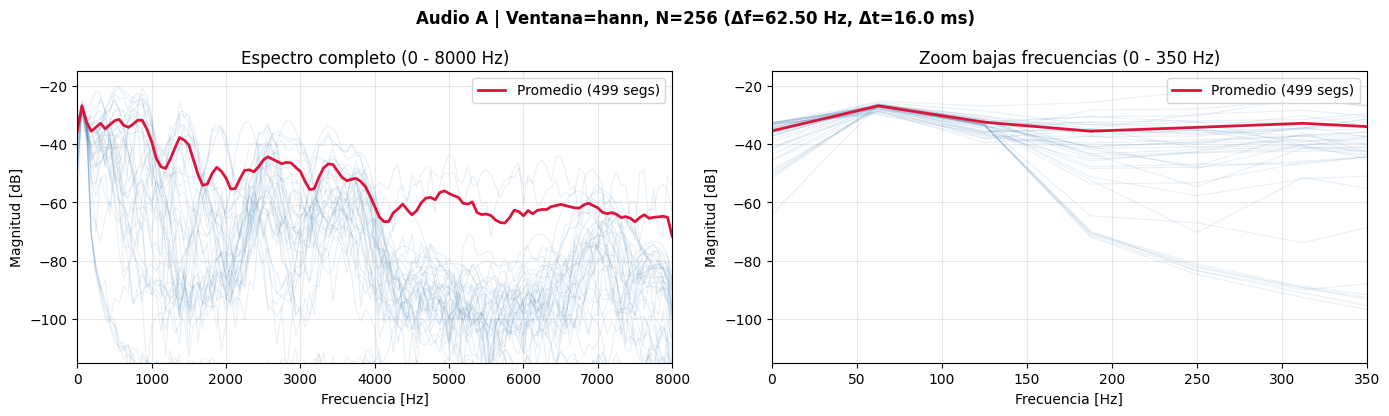

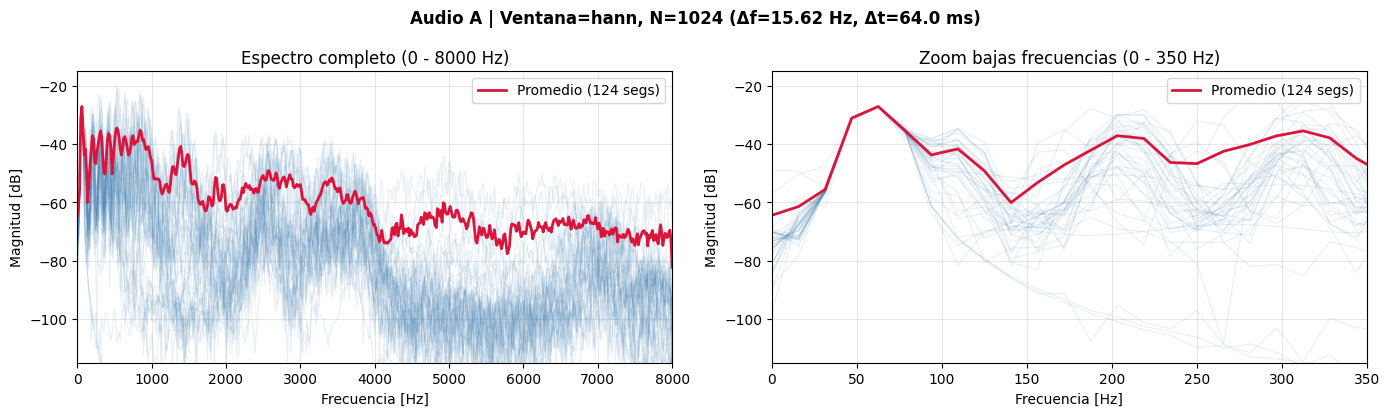

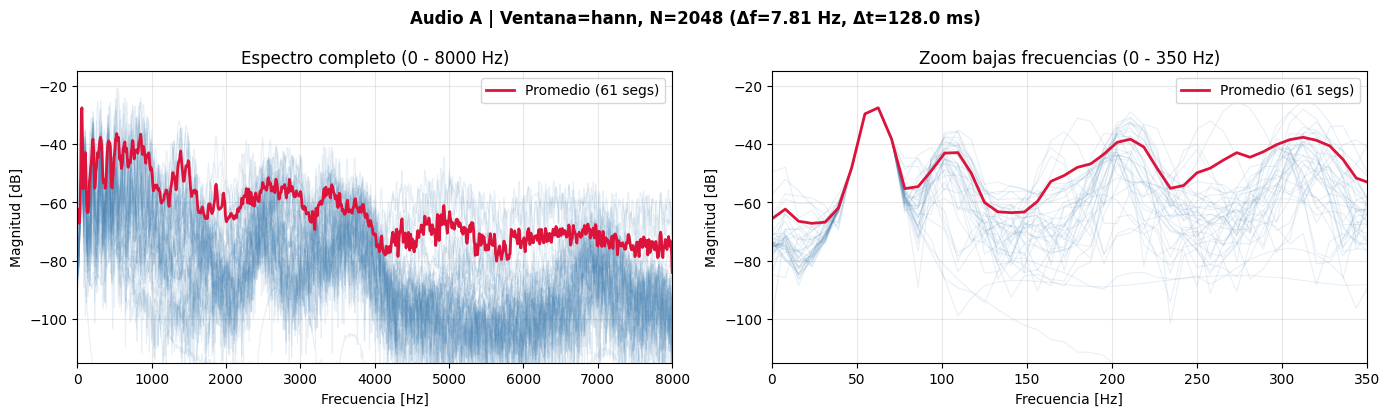

In [ ]:
# Audio A: Comparación de resoluciones (N = 256 vs N = 2048) y Ventana Rectangular vs Hann
graficar_diagnostico_fft(x_a, FS, "Audio A", N=256, ventana="hann", f_zoom=350)
graficar_diagnostico_fft(x_a, FS, "Audio A", N=1024, ventana="hann", f_zoom=350)
graficar_diagnostico_fft(x_a, FS, "Audio A", N=2048, ventana="hann", f_zoom=350)

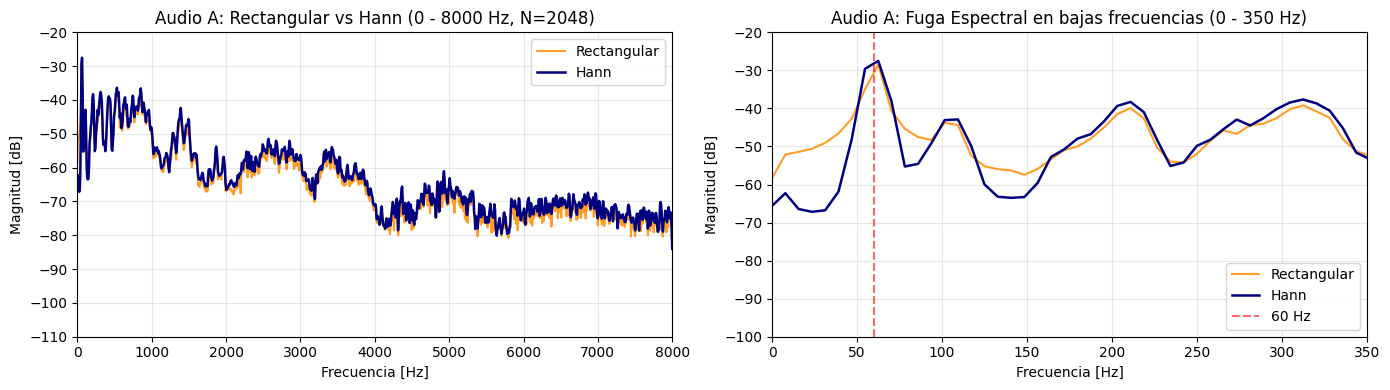

In [ ]:
# Fuga Espectral: Ventana Rectangular vs Ventana Hann (N = 2048)
f_rec_a, _, db_rec_a, _ = calcular_espectros_segmentados(x_a, FS, N=2048, ventana="boxcar")
f_han_a, _, db_han_a, _ = calcular_espectros_segmentados(x_a, FS, N=2048, ventana="hann")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(f_rec_a, db_rec_a, label="Rectangular", color="darkorange", alpha=0.85)
ax1.plot(f_han_a, db_han_a, label="Hann", color="navy", lw=1.8)
ax1.set_xlim(0, 8000); ax1.set_ylim(-110, -20)
ax1.set_title("Audio A: Rectangular vs Hann (0 - 8000 Hz, N=2048)")
ax1.set_xlabel("Frecuencia [Hz]"); ax1.set_ylabel("Magnitud [dB]"); ax1.legend()

ax2.plot(f_rec_a, db_rec_a, label="Rectangular", color="darkorange", alpha=0.85)
ax2.plot(f_han_a, db_han_a, label="Hann", color="navy", lw=1.8)
ax2.axvline(60, color="red", ls="--", alpha=0.6, label="60 Hz")
ax2.set_xlim(0, 350); ax2.set_ylim(-100, -20)
ax2.set_title("Audio A: Fuga Espectral en bajas frecuencias (0 - 350 Hz)")
ax2.set_xlabel("Frecuencia [Hz]"); ax2.set_ylabel("Magnitud [dB]"); ax2.legend()

plt.tight_layout()
plt.show()


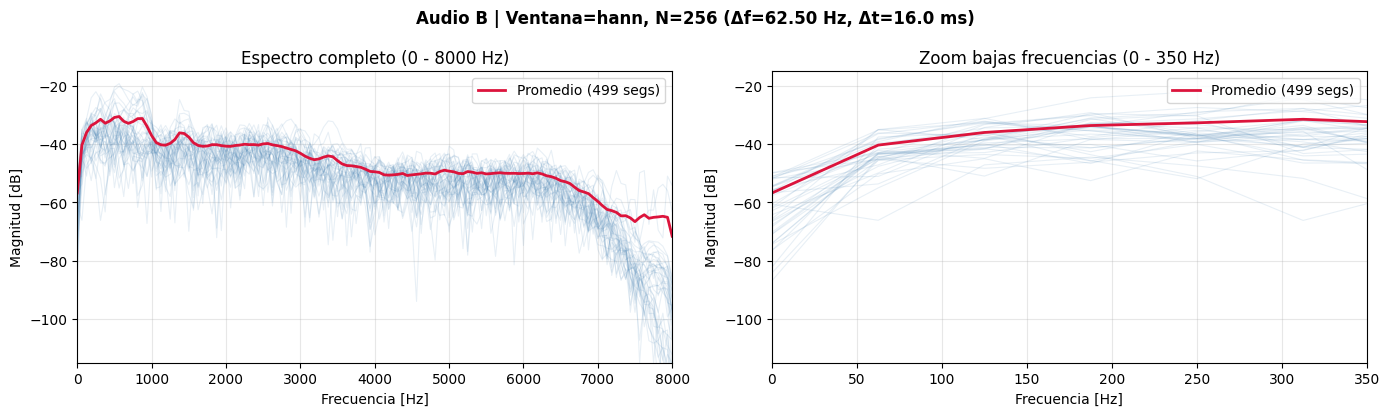

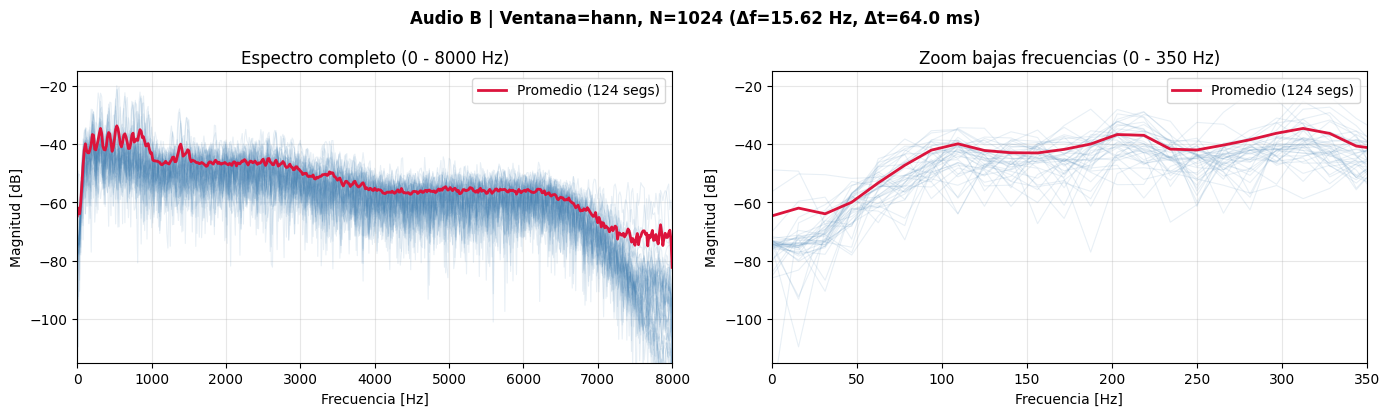

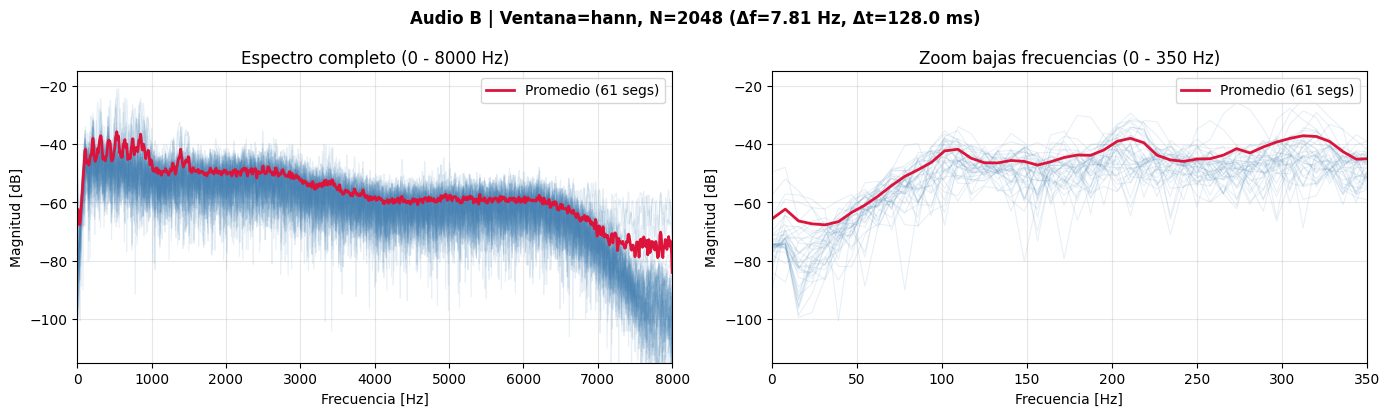

In [ ]:
graficar_diagnostico_fft(x_b, FS, "Audio B", N=256, ventana="hann", f_zoom=350)
graficar_diagnostico_fft(x_b, FS, "Audio B", N=1024, ventana="hann", f_zoom=350)
graficar_diagnostico_fft(x_b, FS, "Audio B", N=2048, ventana="hann", f_zoom=350)

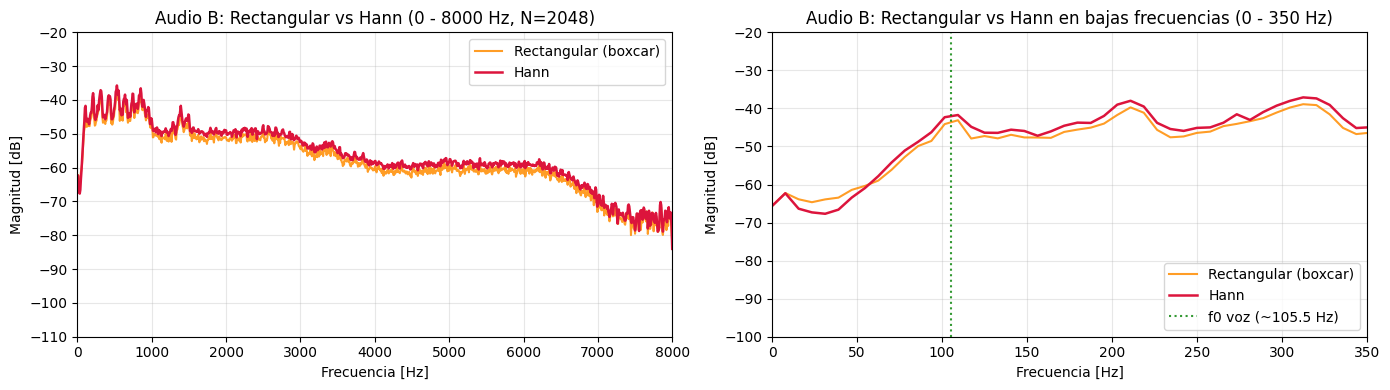

In [ ]:
#Fuga Espectral en Audio B: Ventana Rectangular vs Ventana Hann (N = 2048)
f_rec_b, _, db_rec_b, _ = calcular_espectros_segmentados(x_b, FS, N=2048, ventana="boxcar")
f_han_b, _, db_han_b, _ = calcular_espectros_segmentados(x_b, FS, N=2048, ventana="hann")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(f_rec_b, db_rec_b, label="Rectangular (boxcar)", color="darkorange", alpha=0.85)
ax1.plot(f_han_b, db_han_b, label="Hann", color="crimson", lw=1.8)
ax1.set_xlim(0, 8000); ax1.set_ylim(-110, -20)
ax1.set_title("Audio B: Rectangular vs Hann (0 - 8000 Hz, N=2048)")
ax1.set_xlabel("Frecuencia [Hz]"); ax1.set_ylabel("Magnitud [dB]"); ax1.legend()

ax2.plot(f_rec_b, db_rec_b, label="Rectangular (boxcar)", color="darkorange", alpha=0.85)
ax2.plot(f_han_b, db_han_b, label="Hann", color="crimson", lw=1.8)
ax2.axvline(105.5, color="green", ls=":", alpha=0.8, label="f0 voz (~105.5 Hz)")
ax2.set_xlim(0, 350); ax2.set_ylim(-100, -20)
ax2.set_title("Audio B: Rectangular vs Hann en bajas frecuencias (0 - 350 Hz)")
ax2.set_xlabel("Frecuencia [Hz]"); ax2.set_ylabel("Magnitud [dB]"); ax2.legend()

plt.tight_layout()
plt.show()

# 2. Diseño FIR por Ventanas y Plano Z

Para la implementacio se implementaron las ecuaciones vistas en clase donde para  $N = 2M + 1$ coeficientes desplazados por $M = \frac{N-1}{2}$ muestras:

1. **Estimación de longitud (Diap. 17):** $\Delta f = \frac{|f_{\text{stop}} - f_{\text{pass}}|}{f_s}$, $N \approx \frac{3.1}{\Delta f}$, $M = \frac{N-1}{2}$.
2. **Respuesta ideal desplazada $h_{d2}[n]$:**
   - **Lowpass:** $h_{d2}[n] = \frac{\sin[\omega_c(n-M)]}{\pi(n-M)}$ ($n \ne M$) y $\frac{\omega_c}{\pi}$ ($n = M$).
   - **Highpass:** $h_{d2}[n] = \frac{-\sin[\omega_c(n-M)]}{\pi(n-M)}$ ($n \ne M$) y $\frac{\pi - \omega_c}{\pi}$ ($n = M$).
   - **Band Stop:** $h_{d2}[n] = \frac{-\sin[\omega_2(n-M)]}{\pi(n-M)} + \frac{\sin[\omega_1(n-M)]}{\pi(n-M)}$ ($n \ne M$) y $\frac{\pi - \omega_2 + \omega_1}{\pi}$ ($n = M$).
   - **Band Pass:** $h_{d2}[n] = \frac{\sin[\omega_2(n-M)]}{\pi(n-M)} - \frac{\sin[\omega_1(n-M)]}{\pi(n-M)}$ ($n \ne M$) y $\frac{\omega_2 - \omega_1}{\pi}$ ($n = M$).
3. **Ventana de Hanning / Hann:** $w(n - M) = 0.5 + 0.5\cos\!\left(\frac{\pi(n-M)}{M}\right) \implies b[n] = h_{d2}[n] \cdot w(n-M)$.
4. **Normalización:** $b_1[n] = \frac{b[n]}{\sum_{k=0}^{2M} b[k]}$ (LPF/BSF) o $b_1[n] = \frac{b[n]}{\sum_{k=0}^{2M} (-1)^k b[k]}$ (HPF).

Explicar lo de los silencios y comparaciones XD

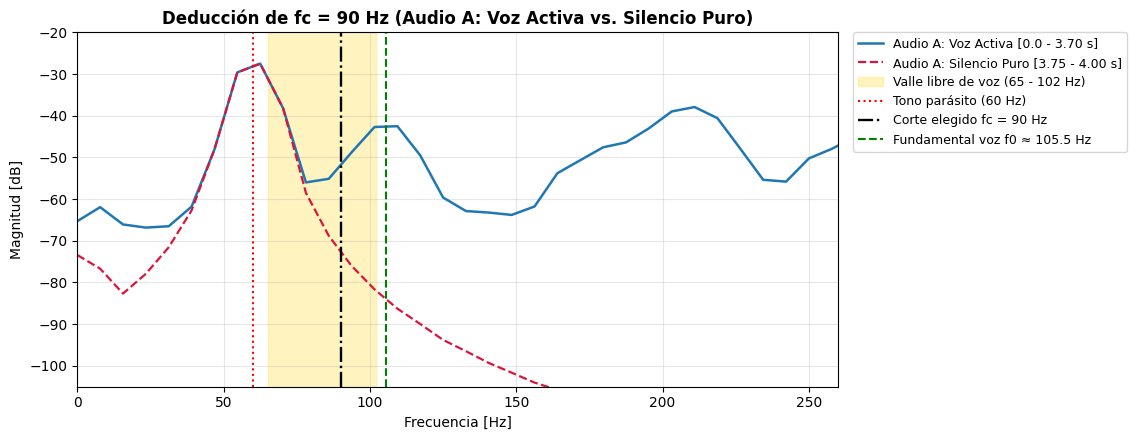

In [ ]:
x_a_act, x_a_sil = x_a[:59200], x_a[60000:]
f_act, _, db_a_act, _ = calcular_espectros_segmentados(x_a_act, FS, N=2048, ventana="hann")
_, _, db_a_sil, _ = calcular_espectros_segmentados(x_a_sil, FS, N=2048, ventana="hann")

fig, ax1 = plt.subplots(figsize=(11.5, 4.5))
ax1.plot(f_act, db_a_act, label="Audio A: Voz Activa [0.0 - 3.70 s]", color="#1f77b4", lw=1.8)
ax1.plot(f_act, db_a_sil, label="Audio A: Silencio Puro [3.75 - 4.00 s]", color="crimson", ls="--", lw=1.6)
ax1.axvspan(65, 102, color="gold", alpha=0.25, label="Valle libre de voz (65 - 102 Hz)")
ax1.axvline(60.0, color="red", ls=":", lw=1.5, label="Tono parásito (60 Hz)")
ax1.axvline(90.0, color="black", ls="-.", lw=1.7, label="Corte elegido fc = 90 Hz")
ax1.axvline(105.5, color="green", ls="--", lw=1.5, label="Fundamental voz f0 ≈ 105.5 Hz")
ax1.set_xlim(0, 260); ax1.set_ylim(-105, -20)
ax1.set_title("Deducción de fc = 90 Hz (Audio A: Voz Activa vs. Silencio Puro)", fontweight="bold")
ax1.set_xlabel("Frecuencia [Hz]"); ax1.set_ylabel("Magnitud [dB]")
ax1.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0.0, fontsize=9)
plt.tight_layout()
plt.show()

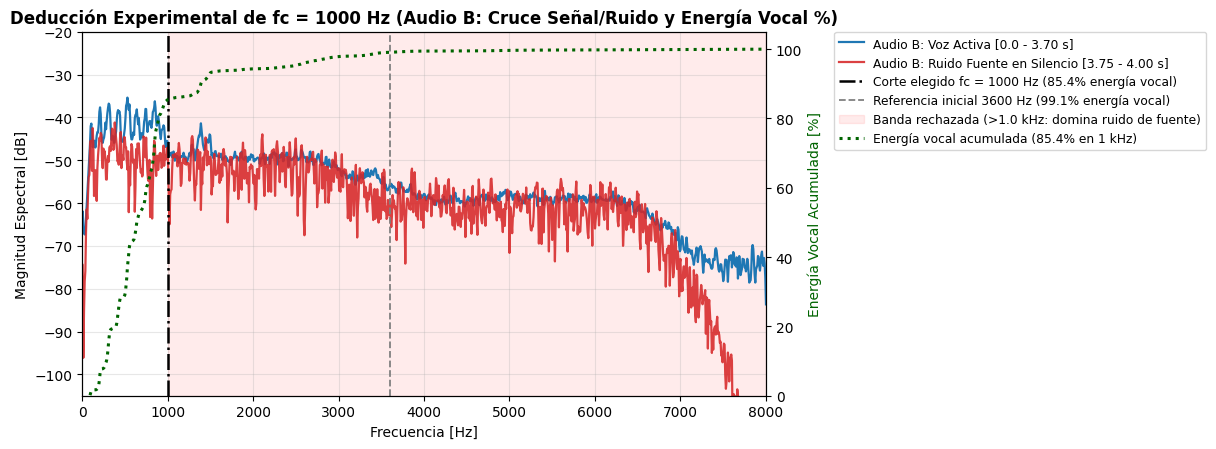

En fc = 1000 Hz se conserva el 85.44% de la energía vocal y se elimina la banda 1000-8000 Hz donde se concentra el ruido de la fuente.


In [ ]:
x_a_act = x_a[:59200]
x_b_act, x_b_sil = x_b[:59200], x_b[60000:]
f_act, _, db_b_act, _ = calcular_espectros_segmentados(x_b_act, FS, N=2048, ventana="hann")
_, _, db_b_sil, _ = calcular_espectros_segmentados(x_b_sil, FS, N=2048, ventana="hann")

# Curva de energía acumulada de la voz limpia (usando Audio A en f >= 90 Hz donde no hay tono de 60 Hz)
f_w, P_a_act = sig.welch(x_a_act, fs=FS, window="hann", nperseg=2048, noverlap=1024, scaling="spectrum")
mask_voz = f_w >= 90.0
f_voz = f_w[mask_voz]
energia_acum_pct = 100.0 * np.cumsum(P_a_act[mask_voz]) / (np.sum(P_a_act[mask_voz]) + 1e-15)
pct_1000_val = energia_acum_pct[np.argmin(np.abs(f_voz - 1000.0))]
pct_3600_val = energia_acum_pct[np.argmin(np.abs(f_voz - 3600.0))]

fig, ax2 = plt.subplots(figsize=(12.5, 4.6))
ax2.plot(f_act, db_b_act, label="Audio B: Voz Activa [0.0 - 3.70 s]", color="#1f77b4", lw=1.6)
ax2.plot(f_act, db_b_sil, label="Audio B: Ruido Fuente en Silencio [3.75 - 4.00 s]", color="#d62728", lw=1.6, alpha=0.88)
ax2.axvline(1000.0, color="black", ls="-.", lw=1.8, label=f"Corte elegido fc = 1000 Hz ({pct_1000_val:.1f}% energía vocal)")
ax2.axvline(3600.0, color="gray", ls="--", lw=1.3, label=f"Referencia inicial 3600 Hz ({pct_3600_val:.1f}% energía vocal)")
ax2.axvspan(1000, 8000, color="red", alpha=0.08, label="Banda rechazada (>1.0 kHz: domina ruido de fuente)")
ax2.set_xlim(0, 8000); ax2.set_ylim(-105, -20)
ax2.set_xlabel("Frecuencia [Hz]"); ax2.set_ylabel("Magnitud Espectral [dB]")

ax2_twin = ax2.twinx()
ax2_twin.plot(f_voz, energia_acum_pct, color="darkgreen", lw=2.2, ls=":", label=f"Energía vocal acumulada (85.4% en 1 kHz)")
ax2_twin.set_ylim(0, 105); ax2_twin.set_ylabel("Energía Vocal Acumulada [%]", color="darkgreen")
ax2_twin.grid(False)

lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, bbox_to_anchor=(1.10, 1), loc="upper left", borderaxespad=0.0, fontsize=8.8)
ax2.set_title("Deducción Experimental de fc = 1000 Hz (Audio B: Cruce Señal/Ruido y Energía Vocal %)", fontweight="bold")
plt.tight_layout()
plt.show()
print(f"En fc = 1000 Hz se conserva el {pct_1000_val:.2f}% de la energía vocal y se elimina la banda 1000-8000 Hz donde se concentra el ruido de la fuente.")

In [ ]:
class FiltroLTI:
    """Representa cualquier bloque de filtro (FIR o IIR)."""
    def __init__(self, nombre, tipo, b, a=None, fs=16000, descripcion=""):
        self.nombre = nombre
        self.tipo = tipo  # "FIR" o "IIR"
        self.b = np.asarray(b, dtype=np.float64)
        self.a = np.array([1.0], dtype=np.float64) if a is None else np.asarray(a, dtype=np.float64)
        self.fs = float(fs)
        self.descripcion = descripcion

    def polos_y_ceros(self):
        # Pad para obtener polos en el origen del FIR si len(b) > len(a)
        L = max(len(self.b), len(self.a))
        b_pad = np.pad(self.b, (0, L - len(self.b)))
        a_pad = np.pad(self.a, (0, L - len(self.a)))
        ceros = np.roots(b_pad) if np.any(b_pad != 0) else np.array([])
        polos = np.roots(a_pad) if len(a_pad) > 1 else np.array([])
        return polos, ceros

    def es_estable(self):
        polos, _ = self.polos_y_ceros()
        if len(polos) == 0:
            return True
        return bool(np.all(np.abs(polos) < 1.0 - 1e-9))

    def respuesta_impulso(self, num_muestras=100):
        imp = np.zeros(num_muestras)
        imp[0] = 1.0
        return sig.lfilter(self.b, self.a, imp)

    def respuesta_frecuencia(self, worN=8192):
        freqs, H = sig.freqz(self.b, self.a, worN=worN, fs=self.fs)
        mag = np.abs(H)
        mag_db = 20.0 * np.log10(mag + 1e-12)
        fase = np.unwrap(np.angle(H))
        return freqs, mag, mag_db, fase

    def complejidad_macs(self):
        # Multiplicaciones y acumulaciones por muestra de salida
        return len(self.b) + (len(self.a) - 1 if len(self.a) > 1 else 0)

    def formato_ecuacion_y_Hz(self, max_terminos=3):
        def fmt_term(c, k, var):
            val_str = f"{c:+.2e}" if (0 < abs(c) < 1e-4) else f"{c:+.5f}"
            if var in ("x", "y"):
                delay = "[n]" if k == 0 else f"[n-{k}]"
                return f"{val_str}·{var}{delay}"
            return f"{val_str}" if k == 0 else f"{val_str}·z^{{-{k}}}"

        def fmt_poly(coeffs, var="x", sign=1.0, offset=0):
            M = len(coeffs)
            if M <= 2 * max_terminos + 2:
                indices = list(range(M))
                grupos = [indices]
            else:
                mid = M // 2
                izq = list(range(max_terminos))
                cen = list(range(mid - 1, mid + 2))
                der = list(range(M - max_terminos, M))
                grupos = [izq, cen, der]

            partes = []
            for g_idx, grp in enumerate(grupos):
                if g_idx > 0:
                    partes.append("...")
                for k in grp:
                    partes.append(fmt_term(sign * coeffs[k], k + offset, var))
            return " ".join(partes)

        b_str = fmt_poly(self.b, "z", 1.0, offset=0)
        a_str = fmt_poly(self.a, "z", 1.0, offset=0) if len(self.a) > 1 else "1"
        x_str = fmt_poly(self.b, "x", 1.0, offset=0)
        y_past = fmt_poly(self.a[1:], "y", -1.0, offset=1) if len(self.a) > 1 else ""
        ec_dif = f"y[n] = {x_str}" + (f" {y_past}" if y_past else "")
        hz_str = f"H(z) = ({b_str}) / ({a_str})"
        return hz_str, ec_dif


def disenar_fir_ventanas(tipo_filtro, fc, fs=16000.0, M=251, ventana="hann"):
    """
    Diseño de filtro FIR por el método de ventanas siguiendo el procedimiento visto en clase:
      - Longitud total de coeficientes: N_coefs = 2*M_delay + 1 (impar)
      - Desplazamiento causal (retardo): M_delay = (N_coefs - 1) // 2
      - Paso 1 y 2: Cálculo de la respuesta ideal desplazada h_d2[n]
        para 0 <= n <= 2*M_delay separando explícitamente n != M_delay y n == M_delay.
      - Paso 3 y 4: Multiplicación por la ecuación explícita de la
        ventana de Hanning (Hann) w[n] evaluada en k = n - M_delay (-M_delay <= k <= M_delay).
      - Normalización: b1[n] = b[n] / sum(b[k]) en LPF/BSF, o
        b1[n] = b[n] / sum((-1)^k * b[k]) en HPF.
    Nota: El parámetro `M` recibido por esta función representa el número total de
    coeficientes N = 2*M_delay + 1
    """
    N_coefs = int(M)
    if N_coefs % 2 == 0:
        N_coefs += 1
    M_delay = (N_coefs - 1) // 2  # M = (N - 1) / 2

    hd2 = np.zeros(N_coefs, dtype=np.float64)

    # Frecuencias angulares normalizadas en radianes/muestra: ω = 2*π*f / fs (0 <= ω <= π)
    if tipo_filtro in ("lowpass", "highpass"):
        wc = 2.0 * np.pi * float(fc) / float(fs)
    else:
        w1 = 2.0 * np.pi * float(fc[0]) / float(fs)
        w2 = 2.0 * np.pi * float(fc[1]) / float(fs)

    # Evaluar término a término para 0 <= n <= 2*M_delay
    for n in range(N_coefs):
        k = n - M_delay  # índice simétrico k in [-M_delay, ..., +M_delay]
        if k == 0:  # Caso n == M_delay
            if tipo_filtro == "lowpass":
                hd2[n] = wc / np.pi
            elif tipo_filtro == "highpass":
                hd2[n] = (np.pi - wc) / np.pi
            elif tipo_filtro == "bandstop":
                hd2[n] = (np.pi - w2 + w1) / np.pi
            elif tipo_filtro == "bandpass":
                hd2[n] = (w2 - w1) / np.pi
            else:
                raise ValueError(f"Tipo FIR no soportado: {tipo_filtro}")
        else:  # Caso n != M_delay
            if tipo_filtro == "lowpass":
                hd2[n] = np.sin(wc * k) / (np.pi * k)
            elif tipo_filtro == "highpass":
                hd2[n] = -np.sin(wc * k) / (np.pi * k)
            elif tipo_filtro == "bandstop":
                hd2[n] = (-np.sin(w2 * k) / (np.pi * k)) + (np.sin(w1 * k) / (np.pi * k))
            elif tipo_filtro == "bandpass":
                hd2[n] = (np.sin(w2 * k) / (np.pi * k)) - (np.sin(w1 * k) / (np.pi * k))
            else:
                raise ValueError(f"Tipo FIR no soportado: {tipo_filtro}")

    # Ecuaciones explícitas de las ventanas
    # Evaluadas en k = n - M_delay para -M_delay <= k <= M_delay:
    k_arr = np.arange(N_coefs, dtype=np.float64) - M_delay
    vent = ventana.lower()
    if vent in ("hann", "hanning"):
        # w(k) = 0.5 + 0.5 * cos(π * k / M)
        w = 0.5 + 0.5 * np.cos(np.pi * k_arr / M_delay)
    elif vent == "hamming":
        # w(k) = 0.54 + 0.46 * cos(π * k / M)
        w = 0.54 + 0.46 * np.cos(np.pi * k_arr / M_delay)
    elif vent == "blackman":
        # w(k) = 0.42 + 0.5 * cos(π * k / M) + 0.08 * cos(2 * π * k / M)
        w = 0.42 + 0.5 * np.cos(np.pi * k_arr / M_delay) + 0.08 * np.cos(2.0 * np.pi * k_arr / M_delay)
    elif vent == "bartlett":
        # w(k) = 1 - |k| / (M + 1)
        w = 1.0 - np.abs(k_arr) / (M_delay + 1.0)
    elif vent in ("boxcar", "rectangular"):
        # w(k) = 1
        w = np.ones(N_coefs, dtype=np.float64)
    else:
        w = sig.get_window(ventana, N_coefs, fftbins=False)

    # Paso 3 y 4 Coeficientes causales enventanados b[n] = h_d2[n] * w[n - M]
    b = hd2 * w

    # Normalización vista
    n_idx = np.arange(N_coefs, dtype=np.float64)
    if tipo_filtro in ("lowpass", "bandstop"):
        #  b1[n] = b[n] / sum_{k=0}^{2M} b[k]  (|H(0)| = 1)
        b1 = b / np.sum(b)
    elif tipo_filtro == "highpass":
        #  b1[n] = b[n] / sum_{k=0}^{2M} (-1)^k b[k]  (|H(π)| = 1)
        b1 = b / np.sum(((-1.0) ** n_idx) * b)
    elif tipo_filtro == "bandpass":
        w_mid = 0.5 * (w1 + w2)
        b1 = b / np.abs(np.sum(b * np.exp(-1j * w_mid * n_idx)))

    nombre = f"FIR {tipo_filtro} (fc={fc} Hz, N={N_coefs} [M={M_delay}], {ventana})"
    return FiltroLTI(nombre=nombre, tipo="FIR", b=b1, a=[1.0], fs=fs)


class PipelinePDS:
    """
    Pipeline: Entrada -> Muestreo -> Bloque PDS (Filtro) -> Reconstrucción -> Diagnóstico y Salida.
    """
    def __init__(self, fs=16000):
        self.fs = fs

    def ejecutar(self, x, filtro: FiltroLTI, modo="fase_cero"):
        if modo == "causal":
            y = sig.lfilter(filtro.b, filtro.a, x)
        elif modo == "fase_cero":
            y = sig.filtfilt(filtro.b, filtro.a, x)
        else:
            raise ValueError("modo debe ser 'causal' o 'fase_cero'")
        residuo = x - y
        return {
            "filtro": filtro,
            "modo": modo,
            "x": x,
            "y": y,
            "residuo": residuo,
        }


def graficar_analisis_lti(filtro: FiltroLTI, zoom_max_hz=None):
    """
    Grafica h[n], Plano Z (ceros y polos), Respuesta en Magnitud (dB) y Fase.
    """
    polos, ceros = filtro.polos_y_ceros()
    h_n = filtro.respuesta_impulso(min(len(filtro.b) if filtro.tipo == "FIR" else 80, 1200))
    freqs, _, mag_db, fase = filtro.respuesta_frecuencia()

    fig, axes = plt.subplots(2, 2, figsize=(13, 8))

    # Respuesta al impulso h[n]
    ax_imp = axes[0, 0]
    if len(h_n) <= 120:
        ax_imp.stem(np.arange(len(h_n)), h_n, basefmt="k-")
    else:
        ax_imp.plot(np.arange(len(h_n)), h_n, lw=1.0, color="teal")
    ax_imp.set_title(f"Respuesta al impulso h[n] ({len(h_n)} muestras mostradas)")
    ax_imp.set_xlabel("n [muestras]"); ax_imp.set_ylabel("h[n]")

    # Plano Z
    ax_z = axes[0, 1]
    theta = np.linspace(0, 2 * np.pi, 400)
    ax_z.plot(np.cos(theta), np.sin(theta), "k--", lw=1.0, alpha=0.6, label="|z|=1")
    ax_z.axhline(0, color="gray", lw=0.6); ax_z.axvline(0, color="gray", lw=0.6)
    if len(ceros) > 0:
        ax_z.scatter(ceros.real, ceros.imag, s=16 if len(ceros) > 100 else 55, facecolors="none", edgecolors="tab:blue", linewidths=1.2, label=f"Ceros ({len(ceros)})")
    if len(polos) > 0:
        # Agrupar polos múltiples en el origen para visualización clara
        origen = np.sum(np.abs(polos) < 1e-8)
        otros_p = polos[np.abs(polos) >= 1e-8]
        if origen > 0:
            ax_z.scatter([0], [0], s=80, marker="x", color="tab:red", linewidths=2.0, label=f"Polos en z=0 (x{origen})")
        if len(otros_p) > 0:
            ax_z.scatter(otros_p.real, otros_p.imag, s=75, marker="x", color="tab:red", linewidths=2.0, label=f"Polos ({len(otros_p)})")
    ax_z.set_aspect("equal")
    lim = max(1.3, min(2.2, np.max(np.abs(ceros)) * 1.1 if len(ceros) else 1.3))
    ax_z.set_xlim(-lim, lim); ax_z.set_ylim(-lim, lim)
    ax_z.set_title(f"Plano Z (Estable BIBO: {'Sí' if filtro.es_estable() else 'No'})")
    ax_z.set_xlabel("Re(z)"); ax_z.set_ylabel("Im(z)"); ax_z.legend(loc="upper right", fontsize=8)

    # Magnitud en dB
    ax_mag = axes[1, 0]
    ax_mag.plot(freqs, mag_db, color="navy", lw=1.6)
    ax_mag.set_xlim(0, zoom_max_hz if zoom_max_hz else filtro.fs / 2.0)
    ax_mag.set_ylim(-85, 5)
    ax_mag.set_title("Respuesta en Magnitud |H(e^jω)| [dB]")
    ax_mag.set_xlabel("Frecuencia [Hz]"); ax_mag.set_ylabel("Magnitud [dB]")

    # Fase desenvuelta
    ax_fas = axes[1, 1]
    ax_fas.plot(freqs, fase, color="purple", lw=1.3)
    ax_fas.set_xlim(0, zoom_max_hz if zoom_max_hz else filtro.fs / 2.0)
    ax_fas.set_title("Respuesta en Fase ∠H(e^jω) [rad]")
    ax_fas.set_xlabel("Frecuencia [Hz]"); ax_fas.set_ylabel("Fase [rad]")

    fig.suptitle(f"Análisis LTI: {filtro.nombre}", fontweight="bold")
    plt.tight_layout()
    plt.show()

    hz_str, ec_dif = filtro.formato_ecuacion_y_Hz()
    print("Función de transferencia:", hz_str)
    print("Ecuación en diferencias :", ec_dif)
    retardo_txt = f"Retardo de grupo lineal α={(len(filtro.b)-1)/2:.1f} muestras ({(len(filtro.b)-1)/(2*filtro.fs)*1000:.2f} ms)" if filtro.tipo == "FIR" else "Fase no lineal (retardo variable con ω)"
    print(f"Complejidad: {filtro.complejidad_macs()} MACs/muestra | {retardo_txt}")

## Tanteo Frecuencias de Corte

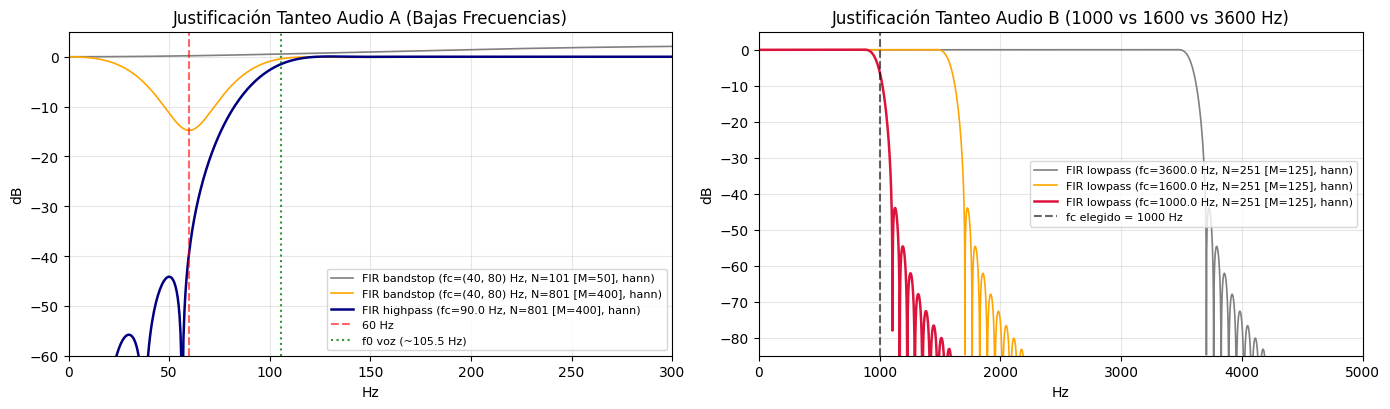

In [ ]:
# Comparación de tanteo para Audio A: Bandstop estrecho vs Highpass
fir_a_tanteo_bs_bajo = disenar_fir_ventanas("bandstop", (40, 80), fs=FS, M=101, ventana="hann")
fir_a_tanteo_bs_alto = disenar_fir_ventanas("bandstop", (40, 80), fs=FS, M=801, ventana="hann")
fir_a_final = disenar_fir_ventanas("highpass", 90.0, fs=FS, M=801, ventana="hann")

# Comparación de tanteo para Audio B: Lowpass 3600 Hz vs Lowpass 1600 Hz vs Lowpass 1000 Hz (Elegido)
fir_b_tanteo_3600 = disenar_fir_ventanas("lowpass", 3600.0, fs=FS, M=251, ventana="hann")
fir_b_tanteo_1600 = disenar_fir_ventanas("lowpass", 1600.0, fs=FS, M=251, ventana="hann")
fir_b_final = disenar_fir_ventanas("lowpass", 1000.0, fs=FS, M=251, ventana="hann")

# Gráfica comparativa del tanteo de magnitudes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
for flt, col in [(fir_a_tanteo_bs_bajo, "gray"), (fir_a_tanteo_bs_alto, "orange"), (fir_a_final, "navy")]:
    fr, _, mdb, _ = flt.respuesta_frecuencia(16384)
    ax1.plot(fr, mdb, label=flt.nombre, color=col, lw=1.8 if flt is fir_a_final else 1.2)
ax1.axvline(60, color="red", ls="--", alpha=0.6, label="60 Hz")
ax1.axvline(105.5, color="green", ls=":", alpha=0.8, label="f0 voz (~105.5 Hz)")
ax1.set_xlim(0, 300); ax1.set_ylim(-60, 5)
ax1.set_title("Justificación Tanteo Audio A (Bajas Frecuencias)"); ax1.set_xlabel("Hz"); ax1.set_ylabel("dB"); ax1.legend(fontsize=8)

for flt, col in [(fir_b_tanteo_3600, "gray"), (fir_b_tanteo_1600, "orange"), (fir_b_final, "crimson")]:
    fr, _, mdb, _ = flt.respuesta_frecuencia(16384)
    ax2.plot(fr, mdb, label=flt.nombre, color=col, lw=1.8 if flt is fir_b_final else 1.2)
ax2.axvline(1000, color="black", ls="--", alpha=0.6, label="fc elegido = 1000 Hz")
ax2.set_xlim(0, 5000); ax2.set_ylim(-85, 5)
ax2.set_title("Justificación Tanteo Audio B (1000 vs 1600 vs 3600 Hz)"); ax2.set_xlabel("Hz"); ax2.set_ylabel("dB"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

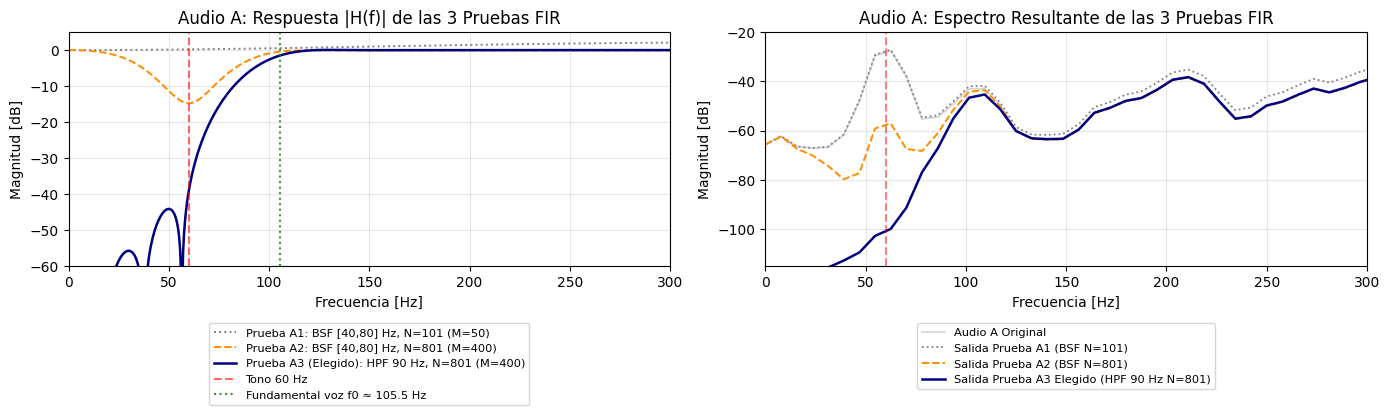

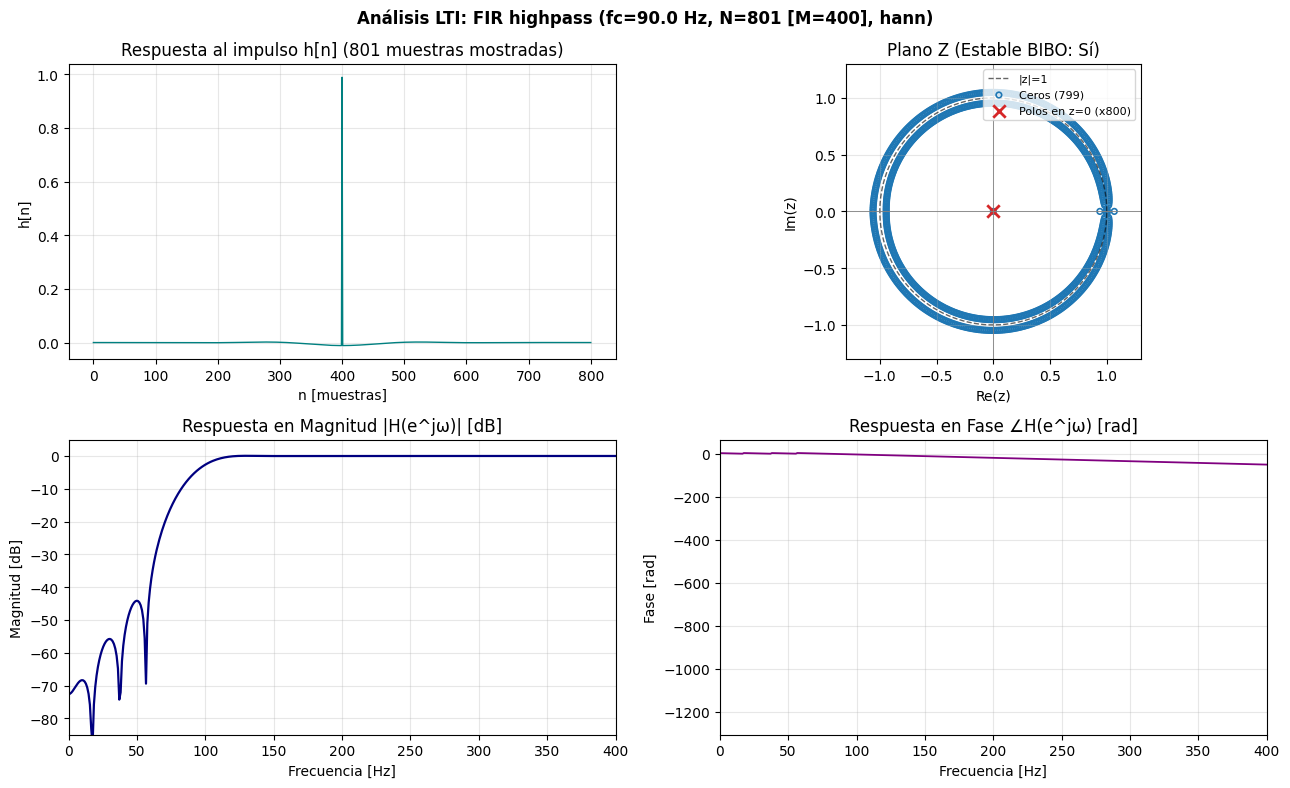

Función de transferencia: H(z) = (-0.00000 -1.23e-08·z^{-1} -4.92e-08·z^{-2} ... -0.01125·z^{-399} +0.98875·z^{-400} -0.01125·z^{-401} ... -4.92e-08·z^{-798} -1.23e-08·z^{-799} -0.00000·z^{-800}) / (1)
Ecuación en diferencias : y[n] = -0.00000·x[n] -1.23e-08·x[n-1] -4.92e-08·x[n-2] ... -0.01125·x[n-399] +0.98875·x[n-400] -0.01125·x[n-401] ... -4.92e-08·x[n-798] -1.23e-08·x[n-799] -0.00000·x[n-800]
Complejidad: 801 MACs/muestra | Retardo de grupo lineal α=400.0 muestras (25.00 ms)


In [ ]:
pipeline = PipelinePDS(FS)

# Definición de las 3 pruebas FIR con Ventana de Hann
fir_a1 = disenar_fir_ventanas("bandstop", (40.0, 80.0), fs=FS, M=101, ventana="hann")   # Prueba A1: BSF orden bajo
fir_a2 = disenar_fir_ventanas("bandstop", (40.0, 80.0), fs=FS, M=801, ventana="hann")   # Prueba A2: BSF orden alto
fir_a3 = disenar_fir_ventanas("highpass", 90.0, fs=FS, M=801, ventana="hann")           # Prueba A3 (Elegido): HPF 90 Hz

res_a1 = pipeline.ejecutar(x_a, fir_a1, modo="fase_cero")
res_a2 = pipeline.ejecutar(x_a, fir_a2, modo="fase_cero")
res_a3 = pipeline.ejecutar(x_a, fir_a3, modo="fase_cero")

# Gráfica comparativa de las 3 pruebas en Audio A: Respuesta |H(f)| y Espectro Filtrado
f_fft, _, db_xa_orig, _ = calcular_espectros_segmentados(x_a, FS, N=2048, ventana="hann")
_, _, db_ya1, _ = calcular_espectros_segmentados(res_a1["y"], FS, N=2048, ventana="hann")
_, _, db_ya2, _ = calcular_espectros_segmentados(res_a2["y"], FS, N=2048, ventana="hann")
_, _, db_ya3, _ = calcular_espectros_segmentados(res_a3["y"], FS, N=2048, ventana="hann")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
for lbl, flt, col, ls in [
    ("Prueba A1: BSF [40,80] Hz, N=101 (M=50)", fir_a1, "gray", ":"),
    ("Prueba A2: BSF [40,80] Hz, N=801 (M=400)", fir_a2, "darkorange", "--"),
    ("Prueba A3 (Elegido): HPF 90 Hz, N=801 (M=400)", fir_a3, "navy", "-"),
]:
    fr, _, mdb, _ = flt.respuesta_frecuencia(16384)
    ax1.plot(fr, mdb, label=lbl, color=col, ls=ls, lw=1.8 if flt is fir_a3 else 1.4)
ax1.axvline(60.0, color="red", ls="--", alpha=0.6, label="Tono 60 Hz")
ax1.axvline(105.5, color="green", ls=":", alpha=0.8, label="Fundamental voz f0 ≈ 105.5 Hz")
ax1.set_xlim(0, 300); ax1.set_ylim(-60, 5)
ax1.set_title("Audio A: Respuesta |H(f)| de las 3 Pruebas FIR")
ax1.set_xlabel("Frecuencia [Hz]"); ax1.set_ylabel("Magnitud [dB]")
ax1.legend(bbox_to_anchor=(0.5, -0.22), loc="upper center", fontsize=8.2)

ax2.plot(f_fft, db_xa_orig, label="Audio A Original", color="lightgray", lw=1.2)
ax2.plot(f_fft, db_ya1, label="Salida Prueba A1 (BSF N=101)", color="gray", ls=":", lw=1.3)
ax2.plot(f_fft, db_ya2, label="Salida Prueba A2 (BSF N=801)", color="darkorange", ls="--", lw=1.4)
ax2.plot(f_fft, db_ya3, label="Salida Prueba A3 Elegido (HPF 90 Hz N=801)", color="navy", lw=1.8)
ax2.axvline(60.0, color="red", ls="--", alpha=0.5)
ax2.set_xlim(0, 300); ax2.set_ylim(-115, -20)
ax2.set_title("Audio A: Espectro Resultante de las 3 Pruebas FIR")
ax2.set_xlabel("Frecuencia [Hz]"); ax2.set_ylabel("Magnitud [dB]")
ax2.legend(bbox_to_anchor=(0.5, -0.22), loc="upper center", fontsize=8.2)
plt.tight_layout()
plt.show()

# Análisis LTI (h[n], Plano Z, Magnitud, Fase, H(z) y Ecuación en Diferencias) del FIR Elegido para Audio A
graficar_analisis_lti(fir_a3, zoom_max_hz=400)


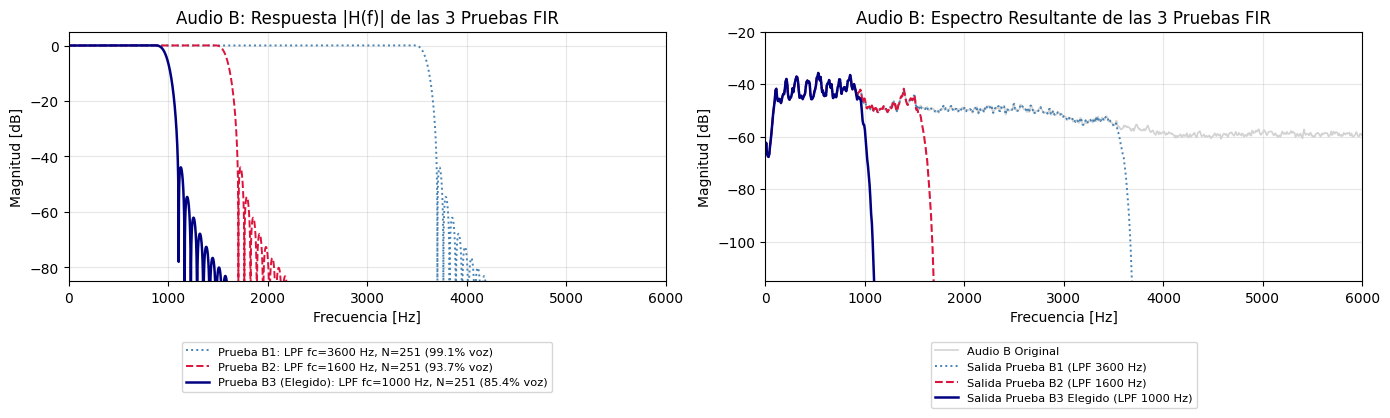

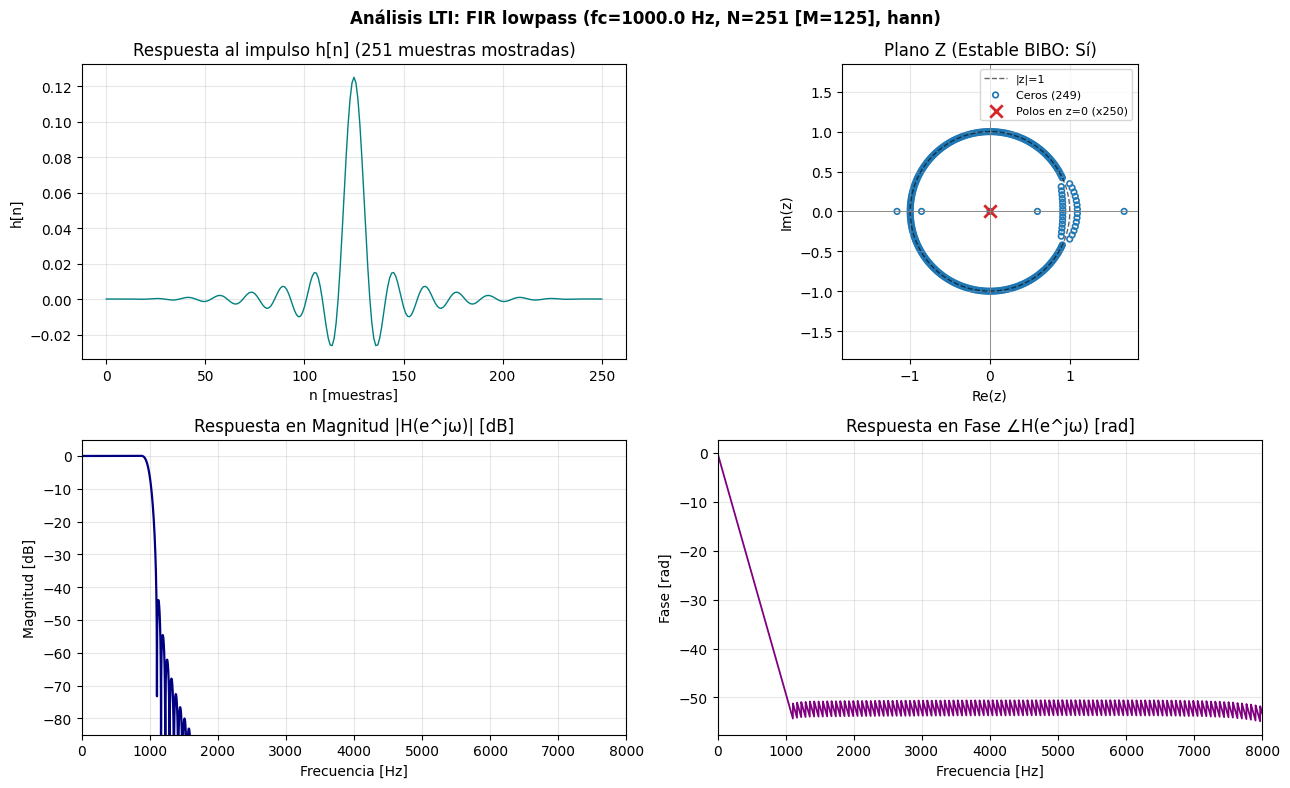

Función de transferencia: H(z) = (-0.00000 -4.05e-07·z^{-1} -1.51e-06·z^{-2} ... +0.12179·z^{-124} +0.12500·z^{-125} +0.12179·z^{-126} ... -1.51e-06·z^{-248} -4.05e-07·z^{-249} -0.00000·z^{-250}) / (1)
Ecuación en diferencias : y[n] = -0.00000·x[n] -4.05e-07·x[n-1] -1.51e-06·x[n-2] ... +0.12179·x[n-124] +0.12500·x[n-125] +0.12179·x[n-126] ... -1.51e-06·x[n-248] -4.05e-07·x[n-249] -0.00000·x[n-250]
Complejidad: 251 MACs/muestra | Retardo de grupo lineal α=125.0 muestras (7.81 ms)


In [ ]:
# Definición de las 3 pruebas FIR Pasa-Bajas con Ventana de Hann (N = 251 [M = 125])
fir_b1 = disenar_fir_ventanas("lowpass", 3600.0, fs=FS, M=251, ventana="hann")  # Prueba B1: LPF 3600 Hz (99.1% energía vocal)
fir_b2 = disenar_fir_ventanas("lowpass", 1600.0, fs=FS, M=251, ventana="hann")  # Prueba B2: LPF 1600 Hz (93.7% energía vocal)
fir_b3 = disenar_fir_ventanas("lowpass", 1000.0, fs=FS, M=251, ventana="hann")  # Prueba B3 (Elegido): LPF 1000 Hz (85.4% energía vocal)

res_b1 = pipeline.ejecutar(x_b, fir_b1, modo="fase_cero")
res_b2 = pipeline.ejecutar(x_b, fir_b2, modo="fase_cero")
res_b3 = pipeline.ejecutar(x_b, fir_b3, modo="fase_cero")

# Gráfica comparativa de las 3 pruebas en Audio B: Respuesta |H(f)| y Espectro Filtrado
f_fft, _, db_xb_orig, _ = calcular_espectros_segmentados(x_b, FS, N=2048, ventana="hann")
_, _, db_yb1, _ = calcular_espectros_segmentados(res_b1["y"], FS, N=2048, ventana="hann")
_, _, db_yb2, _ = calcular_espectros_segmentados(res_b2["y"], FS, N=2048, ventana="hann")
_, _, db_yb3, _ = calcular_espectros_segmentados(res_b3["y"], FS, N=2048, ventana="hann")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
for lbl, flt, col, ls in [
    ("Prueba B1: LPF fc=3600 Hz, N=251 (99.1% voz)", fir_b1, "steelblue", ":"),
    ("Prueba B2: LPF fc=1600 Hz, N=251 (93.7% voz)", fir_b2, "crimson", "--"),
    ("Prueba B3 (Elegido): LPF fc=1000 Hz, N=251 (85.4% voz)", fir_b3, "navy", "-"),
]:
    fr, _, mdb, _ = flt.respuesta_frecuencia(16384)
    ax1.plot(fr, mdb, label=lbl, color=col, ls=ls, lw=1.8 if flt is fir_b3 else 1.4)
ax1.set_xlim(0, 6000); ax1.set_ylim(-85, 5)
ax1.set_title("Audio B: Respuesta |H(f)| de las 3 Pruebas FIR")
ax1.set_xlabel("Frecuencia [Hz]"); ax1.set_ylabel("Magnitud [dB]")
ax1.legend(bbox_to_anchor=(0.5, -0.22), loc="upper center", fontsize=8.2)

ax2.plot(f_fft, db_xb_orig, label="Audio B Original", color="lightgray", lw=1.2)
ax2.plot(f_fft, db_yb1, label="Salida Prueba B1 (LPF 3600 Hz)", color="steelblue", ls=":", lw=1.4)
ax2.plot(f_fft, db_yb2, label="Salida Prueba B2 (LPF 1600 Hz)", color="crimson", ls="--", lw=1.5)
ax2.plot(f_fft, db_yb3, label="Salida Prueba B3 Elegido (LPF 1000 Hz)", color="navy", lw=1.8)
ax2.set_xlim(0, 6000); ax2.set_ylim(-115, -20)
ax2.set_title("Audio B: Espectro Resultante de las 3 Pruebas FIR")
ax2.set_xlabel("Frecuencia [Hz]"); ax2.set_ylabel("Magnitud [dB]")
ax2.legend(bbox_to_anchor=(0.5, -0.22), loc="upper center", fontsize=8.2)
plt.tight_layout()
plt.show()

# Análisis LTI (h[n], Plano Z, Magnitud, Fase, H(z) y Ecuación en Diferencias) del FIR Elegido para Audio B
graficar_analisis_lti(fir_b3, zoom_max_hz=8000)

# 3. Validación mediante IIR

### Justificación de los Filtros IIR Elegidos
- **Audio A (`A_IIR.wav`):** **IIR Notch de 2.º orden ($f_0 = 60\text{ Hz}, Q = 30$).** Coloca dos ceros exactamente sobre el círculo unitario en $60\text{ Hz}$ y dos polos justo detrás ($|p| \approx 0.9996$), logrando un ancho de muesca de apenas $2\text{ Hz}$ con solo **5 MACs/muestra** (frente a $801$ del FIR).
- **Audio B (`B_IIR.wav`):** **IIR Butterworth Pasa-Bajas de orden 6 ($f_c = 1000\text{ Hz}$).** Elegido frente a Chebyshev Tipo I por su respuesta **máximamente plana ($0\text{ dB}$ de rizado)** en la banda vocal ($0\text{--}1000\text{ Hz}$), con pendiente $-36\text{ dB/octava}$ y solo $13\text{ MACs/muestra}$.

In [ ]:
# Audio A: IIR Notch bicuadrático (orden 2) en 60 Hz, Q = 30
b_iir_a, a_iir_a = sig.iirnotch(w0=60.0, Q=30.0, fs=FS)
iir_a_final = FiltroLTI("IIR Notch (f0=60 Hz, Q=30, ord=2)", "IIR", b_iir_a, a_iir_a, fs=FS)

# Alternativa IIR contraste Audio A: Butterworth Pasa-Altas orden 4 en 85 Hz
b_iir_a_hp, a_iir_a_hp = sig.butter(4, 85.0, btype="highpass", fs=FS)
iir_a_butter = FiltroLTI("IIR Butter HPF (fc=85 Hz, ord=4)", "IIR", b_iir_a_hp, a_iir_a_hp, fs=FS)

# Audio B: IIR Butterworth Pasa-Bajas orden 6 en 1000 Hz
b_iir_b, a_iir_b = sig.butter(6, 1000.0, btype="lowpass", fs=FS)
iir_b_final = FiltroLTI("IIR Butter LPF (fc=1000 Hz, ord=6)", "IIR", b_iir_b, a_iir_b, fs=FS)

# Alternativa IIR contraste Audio B: Chebyshev Tipo I orden 6 (rp=0.5 dB) en 1000 Hz
b_iir_b_ch, a_iir_b_ch = sig.cheby1(6, 0.5, 1000.0, btype="lowpass", fs=FS)
iir_b_cheby = FiltroLTI("IIR Cheby1 LPF (fc=1000 Hz, ord=6, rp=0.5 dB)", "IIR", b_iir_b_ch, a_iir_b_ch, fs=FS)

print("Filtros IIR definidos correctamente.")

Filtros IIR definidos correctamente.


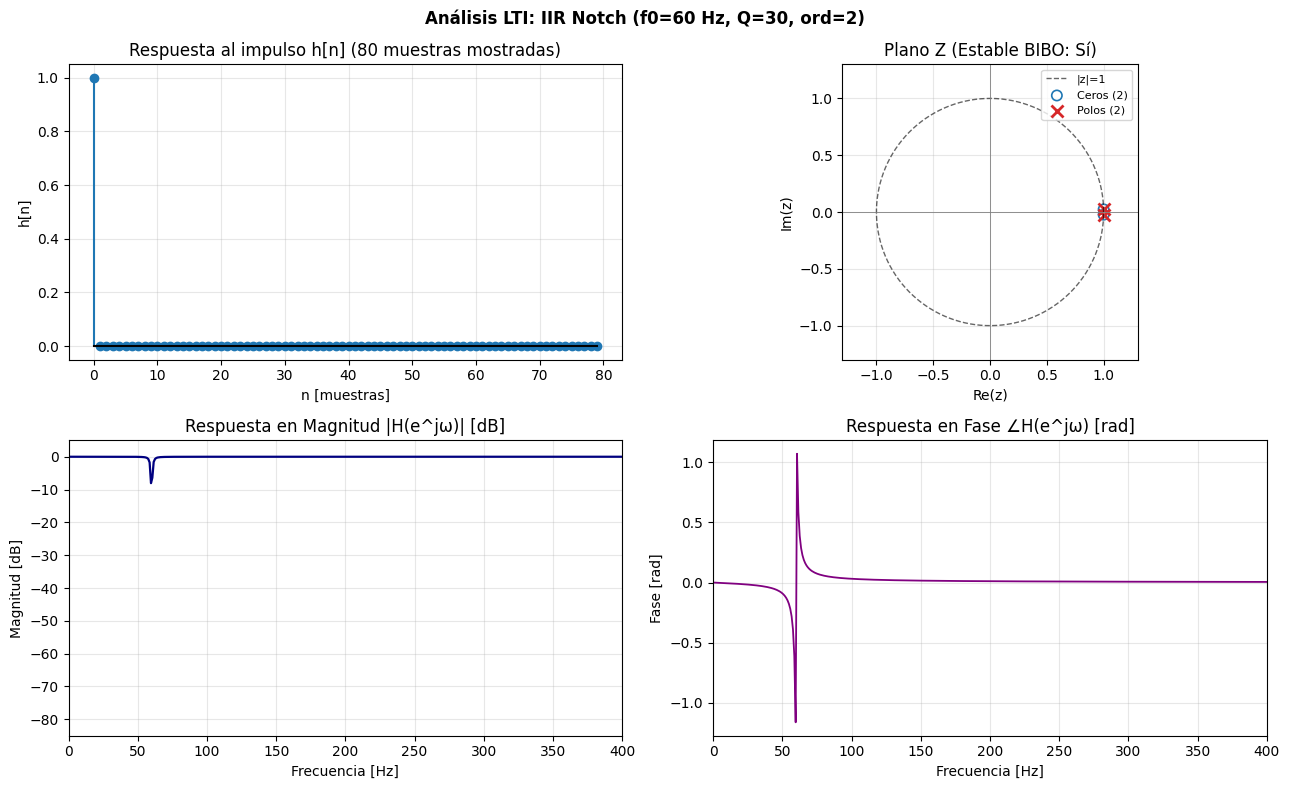

Función de transferencia: H(z) = (+0.99961 -1.99866·z^{-1} +0.99961·z^{-2}) / (+1.00000 -1.99866·z^{-1} +0.99921·z^{-2})
Ecuación en diferencias : y[n] = +0.99961·x[n] -1.99866·x[n-1] +0.99961·x[n-2] +1.99866·y[n-1] -0.99921·y[n-2]
Complejidad: 5 MACs/muestra | Fase no lineal (retardo variable con ω)


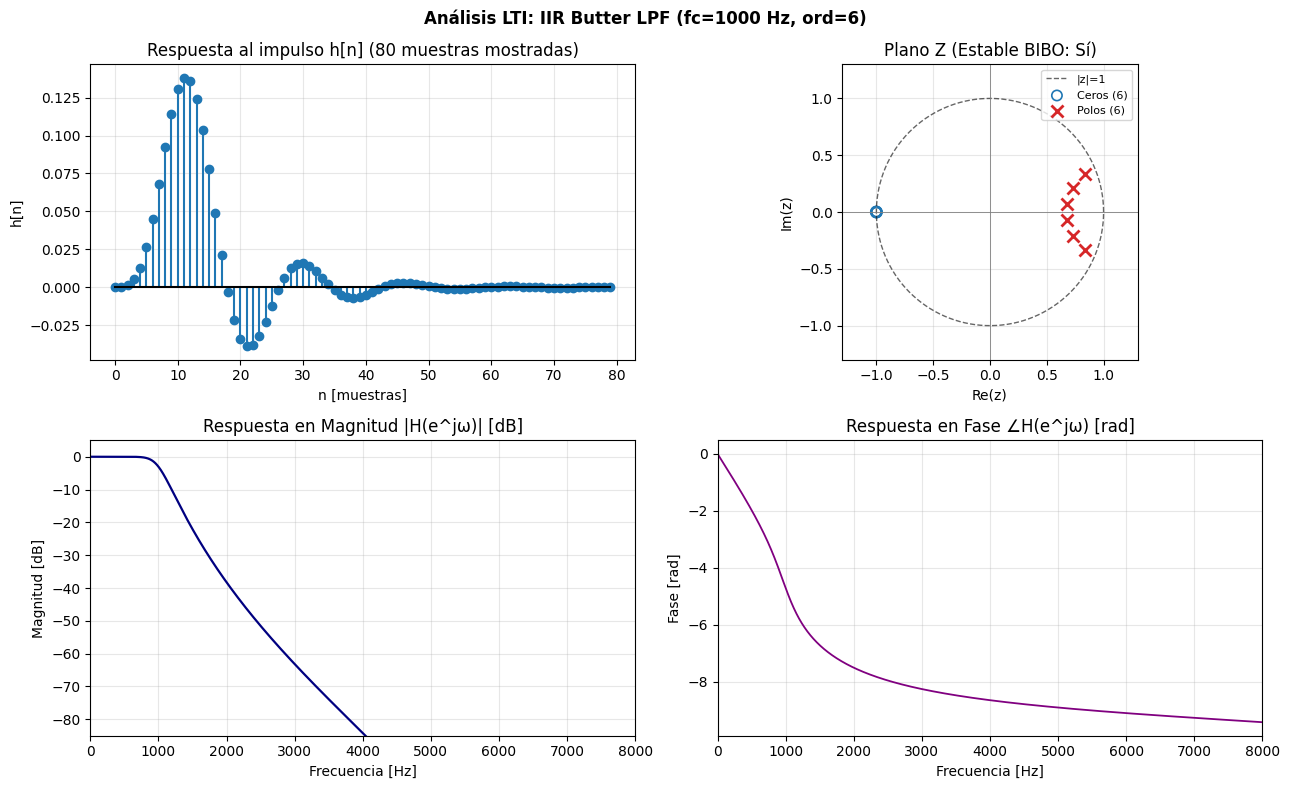

Función de transferencia: H(z) = (+2.88e-05 +0.00017·z^{-1} +0.00043·z^{-2} +0.00058·z^{-3} +0.00043·z^{-4} +0.00017·z^{-5} +2.88e-05·z^{-6}) / (+1.00000 -4.48456·z^{-1} +8.52901·z^{-2} -8.77911·z^{-3} +5.14764·z^{-4} -1.62771·z^{-5} +0.21658·z^{-6})
Ecuación en diferencias : y[n] = +2.88e-05·x[n] +0.00017·x[n-1] +0.00043·x[n-2] +0.00058·x[n-3] +0.00043·x[n-4] +0.00017·x[n-5] +2.88e-05·x[n-6] +4.48456·y[n-1] -8.52901·y[n-2] +8.77911·y[n-3] -5.14764·y[n-4] +1.62771·y[n-5] -0.21658·y[n-6]
Complejidad: 13 MACs/muestra | Fase no lineal (retardo variable con ω)


In [ ]:
graficar_analisis_lti(iir_a_final, zoom_max_hz=400)
graficar_analisis_lti(iir_b_final, zoom_max_hz=8000)

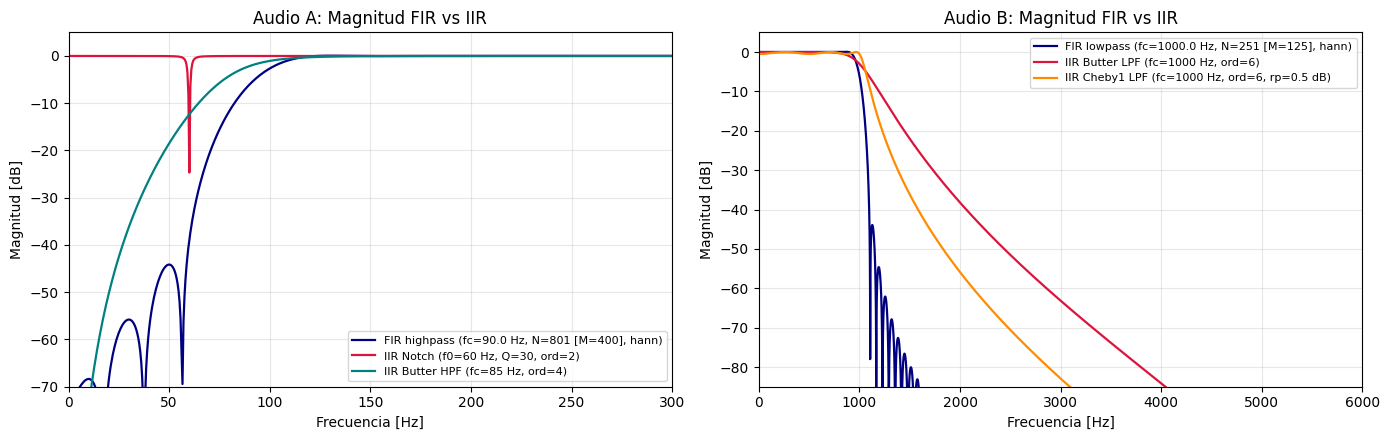

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Comparación para el Audio A (Magnitud)
for flt, col in [(fir_a_final, "navy"), (iir_a_final, "crimson"), (iir_a_butter, "teal")]:
    fr, _, mdb, _ = flt.respuesta_frecuencia(16384)
    axes[0].plot(fr, mdb, label=flt.nombre, color=col, lw=1.6)

axes[0].set_xlim(0, 300)
axes[0].set_ylim(-70, 5)
axes[0].set_title("Audio A: Magnitud FIR vs IIR")
axes[0].set_xlabel("Frecuencia [Hz]")
axes[0].set_ylabel("Magnitud [dB]")
axes[0].legend(fontsize=8)

# Comparación para el Audio B (Magnitud)
for flt, col in [(fir_b_final, "navy"), (iir_b_final, "crimson"), (iir_b_cheby, "darkorange")]:
    fr, _, mdb, _ = flt.respuesta_frecuencia(16384)
    axes[1].plot(fr, mdb, label=flt.nombre, color=col, lw=1.6)

axes[1].set_xlim(0, 6000)
axes[1].set_ylim(-85, 5)
axes[1].set_title("Audio B: Magnitud FIR vs IIR")
axes[1].set_xlabel("Frecuencia [Hz]")
axes[1].set_ylabel("Magnitud [dB]")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

# Ejecución de los pipelines con los filtros IIR
res_a_iir_causal = pipeline.ejecutar(x_a, iir_a_final, modo="causal")
res_a_iir_z = pipeline.ejecutar(x_a, iir_a_final, modo="fase_cero")
res_b_iir_causal = pipeline.ejecutar(x_b, iir_b_final, modo="causal")
res_b_iir_z = pipeline.ejecutar(x_b, iir_b_final, modo="fase_cero")

 ## FIR vs. IIR en Audio B (Voz + 60 Hz)

In [ ]:
res_a_butter_z = pipeline.ejecutar(x_a, iir_a_butter, modo="fase_cero")

print("=== Reproducción Comparativa FIR vs. IIR en Audio A (Voz + 60 Hz) ===")
for txt, sig_arr in [
    ("0) Audio A Original (Voz + Tono 60 Hz):", x_a),
    ("1) Audio A - FIR Elegido (HPF fc=90 Hz, N=801 [M=400]):", res_a_fir_z["y"]),
    ("2) Audio A - IIR Elegido (Notch f0=60 Hz, Q=30, ord=2):", res_a_iir_z["y"]),
    ("3) Audio A - IIR Contraste (Butterworth HPF fc=85 Hz, ord=4):", res_a_butter_z["y"]),
]:
    print(txt)
    display(Audio(sig_arr, rate=FS))

=== Reproducción Comparativa FIR vs. IIR en Audio A (Voz + 60 Hz) ===
0) Audio A Original (Voz + Tono 60 Hz):


1) Audio A - FIR Elegido (HPF fc=90 Hz, N=801 [M=400]):


2) Audio A - IIR Elegido (Notch f0=60 Hz, Q=30, ord=2):


3) Audio A - IIR Contraste (Butterworth HPF fc=85 Hz, ord=4):


 ## FIR vs. IIR en Audio B (Voz + Fuente de Agua)

In [ ]:
res_b_cheby_z = pipeline.ejecutar(x_b, iir_b_cheby, modo="fase_cero")

print("=== Reproducción Comparativa FIR vs. IIR en Audio B (Voz + Fuente de Agua) ===")
for txt, sig_arr in [
    ("0) Audio B Original (Voz + Fuente de agua):", x_b),
    ("1) Audio B - FIR Elegido (LPF fc=1000 Hz, N=251 [M=125]):", res_b_fir_z["y"]),
    ("2) Audio B - IIR Elegido (Butterworth LPF fc=1000 Hz, ord=6):", res_b_iir_z["y"]),
    ("3) Audio B - IIR Contraste (Chebyshev Tipo I LPF fc=1000 Hz, ord=6, rp=0.5 dB):", res_b_cheby_z["y"]),
]:
    print(txt)
    display(Audio(sig_arr, rate=FS))

=== Reproducción Comparativa FIR vs. IIR en Audio B (Voz + Fuente de Agua) ===
0) Audio B Original (Voz + Fuente de agua):


1) Audio B - FIR Elegido (LPF fc=1000 Hz, N=251 [M=125]):


2) Audio B - IIR Elegido (Butterworth LPF fc=1000 Hz, ord=6):


3) Audio B - IIR Contraste (Chebyshev Tipo I LPF fc=1000 Hz, ord=6, rp=0.5 dB):


# 4. Discusión de Resultados

=== TABLA DE MEDICIONES CUANTITATIVAS POR CASO (dB) ===
Señal Evaluada               | Banda 50-70Hz |  Voz 100-1.0k |  Alta 1.0k-8k | Pausa [3.75-4s]
--------------------------------------------------------------------------------------------
Audio A Original             |      -28.43 dB |      -24.78 dB |      -32.53 dB |        -29.95 dB
A_FIR (HPF 90Hz N=801)       |     -101.15 dB |      -24.82 dB |      -32.53 dB |        -72.99 dB
A_IIR (Notch 60Hz ord=2)     |      -53.14 dB |      -24.78 dB |      -32.53 dB |        -74.16 dB
Audio B Original             |      -59.08 dB |      -23.58 dB |      -26.84 dB |        -27.34 dB
B_FIR (LPF 1.0kHz N=251)     |      -59.08 dB |      -23.70 dB |      -58.02 dB |        -31.25 dB
B_IIR (Butter 1.0kHz o=6)    |      -59.08 dB |      -23.95 dB |      -47.81 dB |        -31.32 dB

=== RESUMEN DE MEJORAS CUANTITATIVAS ===
• Audio A (Atenuación puntual en 60.00 Hz, Δf=0.25 Hz):
    - A_FIR (HPF 90 Hz, N=801) : -78.12 dB de reducción en 60 Hz

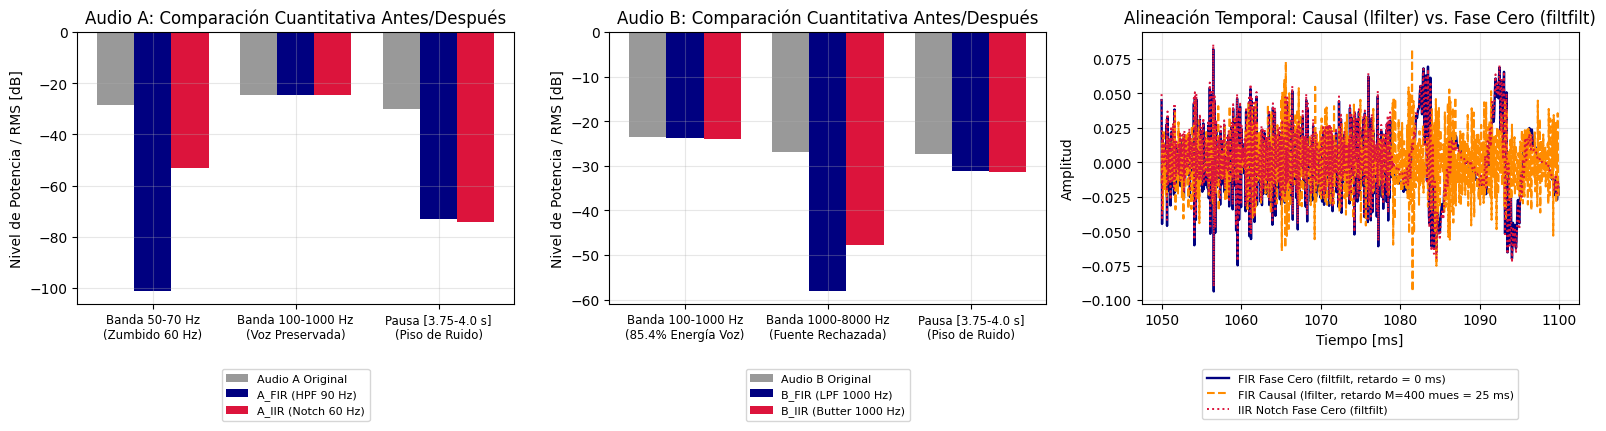

In [ ]:
def potencia_banda_db(x, fs, f_low, f_high):
    f, Pxx = sig.welch(x, fs=fs, window="hann", nperseg=2048, noverlap=1024, scaling="spectrum")
    mask = (f >= f_low) & (f <= f_high)
    return float(10.0 * np.log10(np.sum(Pxx[mask]) + 1e-15))

sil_slice = slice(60000, 64000)  # [3.75 s - 4.00 s]: pausa vocal pura sin locución
def rms_db(sig_arr):
    return float(20.0 * np.log10(np.sqrt(np.mean(sig_arr**2)) + 1e-15))

# Medición puntual exacta en el bin de 60.00 Hz (FFT completa 64,000 muestras -> Δf = 0.25 Hz)
f_full = np.fft.rfftfreq(len(x_a), 1.0 / FS)
idx_60 = np.argmin(np.abs(f_full - 60.0))
w_full = np.hanning(len(x_a))
mag60 = lambda s: float(20.0 * np.log10(np.abs(np.fft.rfft(s * w_full))[idx_60] + 1e-12))
p60_xa = mag60(x_a)
p60_af = mag60(res_a_fir_z["y"])
p60_ai = mag60(res_a_iir_z["y"])

# Tabla resumen cuantitativa por bandas espectrales y piso de ruido en pausa vocal
filas = [
    ("Audio A Original",          potencia_banda_db(x_a, FS, 50, 70),              potencia_banda_db(x_a, FS, 100, 1000),              potencia_banda_db(x_a, FS, 1000, 8000),              rms_db(x_a[sil_slice])),
    ("A_FIR (HPF 90Hz N=801)",    potencia_banda_db(res_a_fir_z["y"], FS, 50, 70), potencia_banda_db(res_a_fir_z["y"], FS, 100, 1000), potencia_banda_db(res_a_fir_z["y"], FS, 1000, 8000), rms_db(res_a_fir_z["y"][sil_slice])),
    ("A_IIR (Notch 60Hz ord=2)",  potencia_banda_db(res_a_iir_z["y"], FS, 50, 70), potencia_banda_db(res_a_iir_z["y"], FS, 100, 1000), potencia_banda_db(res_a_iir_z["y"], FS, 1000, 8000), rms_db(res_a_iir_z["y"][sil_slice])),
    ("Audio B Original",          potencia_banda_db(x_b, FS, 50, 70),              potencia_banda_db(x_b, FS, 100, 1000),              potencia_banda_db(x_b, FS, 1000, 8000),              rms_db(x_b[sil_slice])),
    ("B_FIR (LPF 1.0kHz N=251)",  potencia_banda_db(res_b_fir_z["y"], FS, 50, 70), potencia_banda_db(res_b_fir_z["y"], FS, 100, 1000), potencia_banda_db(res_b_fir_z["y"], FS, 1000, 8000), rms_db(res_b_fir_z["y"][sil_slice])),
    ("B_IIR (Butter 1.0kHz o=6)", potencia_banda_db(res_b_iir_z["y"], FS, 50, 70), potencia_banda_db(res_b_iir_z["y"], FS, 100, 1000), potencia_banda_db(res_b_iir_z["y"], FS, 1000, 8000), rms_db(res_b_iir_z["y"][sil_slice])),
]

print("=== TABLA DE MEDICIONES CUANTITATIVAS POR CASO (dB) ===")
print(f"{'Señal Evaluada':<28} | {'Banda 50-70Hz':>13} | {'Voz 100-1.0k':>13} | {'Alta 1.0k-8k':>13} | {'Pausa [3.75-4s]':>15}")
print("-" * 92)
for nom, b60, bvoz, balt, bsil in filas:
    print(f"{nom:<28} | {b60:11.2f} dB | {bvoz:11.2f} dB | {balt:11.2f} dB | {bsil:13.2f} dB")

print("\n=== RESUMEN DE MEJORAS CUANTITATIVAS ===")
print(f"• Audio A (Atenuación puntual en 60.00 Hz, Δf=0.25 Hz):")
print(f"    - A_FIR (HPF 90 Hz, N=801) : -{p60_xa - p60_af:.2f} dB de reducción en 60 Hz | Reducción RMS en pausa vocal: -{filas[0][4] - filas[1][4]:.2f} dB | Variación banda vocal: {filas[1][2] - filas[0][2]:+.2f} dB")
print(f"    - A_IIR (Notch 60 Hz, Q=30): -{p60_xa - p60_ai:.2f} dB de reducción en 60 Hz | Reducción RMS en pausa vocal: -{filas[0][4] - filas[2][4]:.2f} dB | Variación banda vocal: {filas[2][2] - filas[0][2]:+.2f} dB")
print(f"• Audio B (Supresión de ruido de fuente en banda 1000-8000 Hz y pausa vocal):")
print(f"    - B_FIR (LPF 1000 Hz, N=251): -{filas[3][3] - filas[4][3]:.2f} dB en 1.0-8.0 kHz | Reducción RMS en pausa vocal: -{filas[3][4] - filas[4][4]:.2f} dB | Variación banda vocal (100-1000 Hz): {filas[4][2] - filas[3][2]:+.2f} dB")
print(f"    - B_IIR (Butter 1000 Hz, o6): -{filas[3][3] - filas[5][3]:.2f} dB en 1.0-8.0 kHz | Reducción RMS en pausa vocal: -{filas[3][4] - filas[5][4]:.2f} dB | Variación banda vocal (100-1000 Hz): {filas[5][2] - filas[3][2]:+.2f} dB")

# Gráfica comparativa de métricas cuantitativas + Verificación temporal Causal (lfilter) vs Fase Cero (filtfilt)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# Subgráfica 1: Métricas Audio A
cats_a = ["Banda 50-70 Hz\n(Zumbido 60 Hz)", "Banda 100-1000 Hz\n(Voz Preservada)", "Pausa [3.75-4.0 s]\n(Piso de Ruido)"]
vals_a_orig = [filas[0][1], filas[0][2], filas[0][4]]
vals_a_fir  = [filas[1][1], filas[1][2], filas[1][4]]
vals_a_iir  = [filas[2][1], filas[2][2], filas[2][4]]
x_pos = np.arange(len(cats_a))
w_bar = 0.26
axes[0].bar(x_pos - w_bar, vals_a_orig, width=w_bar, label="Audio A Original", color="gray", alpha=0.8)
axes[0].bar(x_pos,         vals_a_fir,  width=w_bar, label="A_FIR (HPF 90 Hz)", color="navy")
axes[0].bar(x_pos + w_bar, vals_a_iir,  width=w_bar, label="A_IIR (Notch 60 Hz)", color="crimson")
axes[0].set_xticks(x_pos); axes[0].set_xticklabels(cats_a, fontsize=8.5)
axes[0].set_ylabel("Nivel de Potencia / RMS [dB]")
axes[0].set_title("Audio A: Comparación Cuantitativa Antes/Después")
axes[0].legend(bbox_to_anchor=(0.5, -0.22), loc="upper center", fontsize=8)

# Subgráfica 2: Métricas Audio B
cats_b = ["Banda 100-1000 Hz\n(85.4% Energía Voz)", "Banda 1000-8000 Hz\n(Fuente Rechazada)", "Pausa [3.75-4.0 s]\n(Piso de Ruido)"]
vals_b_orig = [filas[3][2], filas[3][3], filas[3][4]]
vals_b_fir  = [filas[4][2], filas[4][3], filas[4][4]]
vals_b_iir  = [filas[5][2], filas[5][3], filas[5][4]]
axes[1].bar(x_pos - w_bar, vals_b_orig, width=w_bar, label="Audio B Original", color="gray", alpha=0.8)
axes[1].bar(x_pos,         vals_b_fir,  width=w_bar, label="B_FIR (LPF 1000 Hz)", color="navy")
axes[1].bar(x_pos + w_bar, vals_b_iir,  width=w_bar, label="B_IIR (Butter 1000 Hz)", color="crimson")
axes[1].set_xticks(x_pos); axes[1].set_xticklabels(cats_b, fontsize=8.5)
axes[1].set_ylabel("Nivel de Potencia / RMS [dB]")
axes[1].set_title("Audio B: Comparación Cuantitativa Antes/Después")
axes[1].legend(bbox_to_anchor=(0.5, -0.22), loc="upper center", fontsize=8)

# Subgráfica 3: Efecto en el tiempo del retardo causal M=(N-1)/2 en lfilter vs alineación exacta en filtfilt
idx_z = slice(16800, 17600)  # ventana de 50 ms con fonema vocal activo (1.05 s - 1.10 s)
axes[2].plot(t_a[idx_z] * 1000, res_a_fir_z["y"][idx_z], label="FIR Fase Cero (filtfilt, retardo = 0 ms)", color="navy", lw=1.7)
axes[2].plot(t_a[idx_z] * 1000, res_a_fir_causal["y"][idx_z], label="FIR Causal (lfilter, retardo M=400 mues = 25 ms)", color="darkorange", ls="--", lw=1.5)
axes[2].plot(t_a[idx_z] * 1000, res_a_iir_z["y"][idx_z], label="IIR Notch Fase Cero (filtfilt)", color="crimson", ls=":", lw=1.4)
axes[2].set_title("Alineación Temporal: Causal (lfilter) vs. Fase Cero (filtfilt)")
axes[2].set_xlabel("Tiempo [ms]"); axes[2].set_ylabel("Amplitud")
axes[2].legend(bbox_to_anchor=(0.5, -0.22), loc="upper center", fontsize=8)

plt.tight_layout()
plt.show()


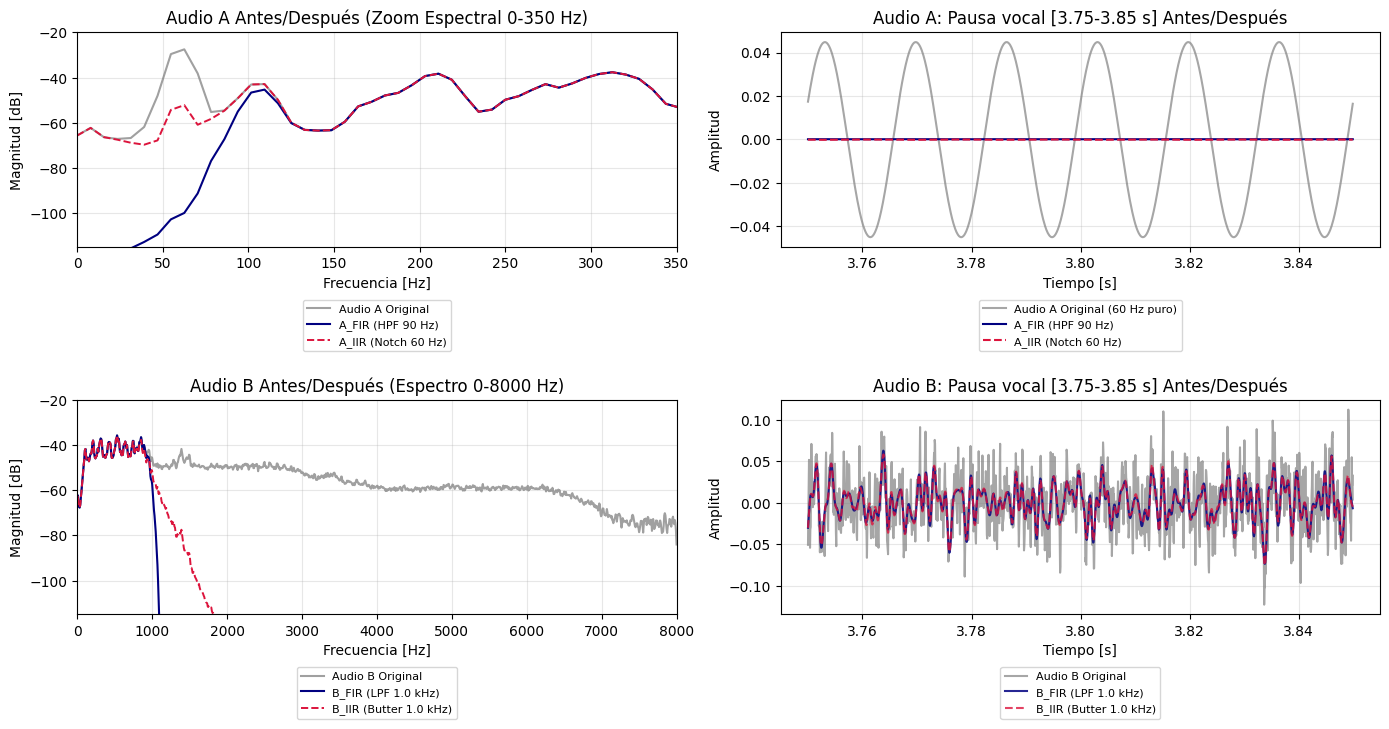

Archivos exportados exitosamente:
 -> /content/output/A_FIR.wav
 -> /content/output/A_IIR.wav
 -> /content/output/B_FIR.wav
 -> /content/output/B_IIR.wav

=== Reproductores Finales Antes y Después (FIR e IIR) ===
Audio A Original (Voz + Tono de 60 Hz):


A_FIR.wav (FIR HPF fc=90 Hz, N=801 [M=400], fase cero):


A_IIR.wav (IIR Notch f0=60 Hz, Q=30, ord=2, fase cero):


Audio B Original (Voz + Fuente de agua):


B_FIR.wav (FIR LPF fc=1000 Hz, N=251 [M=125], fase cero):


B_IIR.wav (IIR Butterworth LPF fc=1000 Hz, ord=6, fase cero):


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5))
f, _, db_xa, _ = calcular_espectros_segmentados(x_a, FS, N=2048, ventana="hann")
_, _, db_af, _ = calcular_espectros_segmentados(res_a_fir_z["y"], FS, N=2048, ventana="hann")
_, _, db_ai, _ = calcular_espectros_segmentados(res_a_iir_z["y"], FS, N=2048, ventana="hann")

_, _, db_xb, _ = calcular_espectros_segmentados(x_b, FS, N=2048, ventana="hann")
_, _, db_bf, _ = calcular_espectros_segmentados(res_b_fir_z["y"], FS, N=2048, ventana="hann")
_, _, db_bi, _ = calcular_espectros_segmentados(res_b_iir_z["y"], FS, N=2048, ventana="hann")

axes[0, 0].plot(f, db_xa, label="Audio A Original", color="gray", alpha=0.75)
axes[0, 0].plot(f, db_af, label="A_FIR (HPF 90 Hz)", color="navy", lw=1.5)
axes[0, 0].plot(f, db_ai, label="A_IIR (Notch 60 Hz)", color="crimson", ls="--", lw=1.4)
axes[0, 0].set_xlim(0, 350); axes[0, 0].set_ylim(-115, -20)
axes[0, 0].set_title("Audio A Antes/Después (Zoom Espectral 0-350 Hz)")
axes[0, 0].set_xlabel("Frecuencia [Hz]"); axes[0, 0].set_ylabel("Magnitud [dB]")
axes[0, 0].legend(bbox_to_anchor=(0.5, -0.22), loc="upper center", fontsize=8)

axes[0, 1].plot(t_a[60000:61600], x_a[60000:61600], label="Audio A Original (60 Hz puro)", color="gray", alpha=0.7)
axes[0, 1].plot(t_a[60000:61600], res_a_fir_z["y"][60000:61600], label="A_FIR (HPF 90 Hz)", color="navy")
axes[0, 1].plot(t_a[60000:61600], res_a_iir_z["y"][60000:61600], label="A_IIR (Notch 60 Hz)", color="crimson", ls="--")
axes[0, 1].set_title("Audio A: Pausa vocal [3.75-3.85 s] Antes/Después")
axes[0, 1].set_xlabel("Tiempo [s]"); axes[0, 1].set_ylabel("Amplitud")
axes[0, 1].legend(bbox_to_anchor=(0.5, -0.22), loc="upper center", fontsize=8)

axes[1, 0].plot(f, db_xb, label="Audio B Original", color="gray", alpha=0.75)
axes[1, 0].plot(f, db_bf, label="B_FIR (LPF 1.0 kHz)", color="navy", lw=1.5)
axes[1, 0].plot(f, db_bi, label="B_IIR (Butter 1.0 kHz)", color="crimson", ls="--", lw=1.4)
axes[1, 0].set_xlim(0, 8000); axes[1, 0].set_ylim(-115, -20)
axes[1, 0].set_title("Audio B Antes/Después (Espectro 0-8000 Hz)")
axes[1, 0].set_xlabel("Frecuencia [Hz]"); axes[1, 0].set_ylabel("Magnitud [dB]")
axes[1, 0].legend(bbox_to_anchor=(0.5, -0.22), loc="upper center", fontsize=8)

axes[1, 1].plot(t_b[60000:61600], x_b[60000:61600], label="Audio B Original", color="gray", alpha=0.7)
axes[1, 1].plot(t_b[60000:61600], res_b_fir_z["y"][60000:61600], label="B_FIR (LPF 1.0 kHz)", color="navy", alpha=0.85)
axes[1, 1].plot(t_b[60000:61600], res_b_iir_z["y"][60000:61600], label="B_IIR (Butter 1.0 kHz)", color="crimson", ls="--", alpha=0.8)
axes[1, 1].set_title("Audio B: Pausa vocal [3.75-3.85 s] Antes/Después")
axes[1, 1].set_xlabel("Tiempo [s]"); axes[1, 1].set_ylabel("Amplitud")
axes[1, 1].legend(bbox_to_anchor=(0.5, -0.22), loc="upper center", fontsize=8)

plt.tight_layout()
plt.show()

# Exportación de los 4 archivos WAV requeridos
rutas_out = {
    "A_FIR.wav": exportar_wav_16bit(os.path.join(OUTPUT_DIR, "A_FIR.wav"), FS, res_a_fir_z["y"]),
    "A_IIR.wav": exportar_wav_16bit(os.path.join(OUTPUT_DIR, "A_IIR.wav"), FS, res_a_iir_z["y"]),
    "B_FIR.wav": exportar_wav_16bit(os.path.join(OUTPUT_DIR, "B_FIR.wav"), FS, res_b_fir_z["y"]),
    "B_IIR.wav": exportar_wav_16bit(os.path.join(OUTPUT_DIR, "B_IIR.wav"), FS, res_b_iir_z["y"]),
}
print("Archivos exportados exitosamente:")
for k, v in rutas_out.items():
    print(" ->", os.path.abspath(v))

# Reproductores de escucha comparativa final
print("\n=== Reproductores Finales Antes y Después (FIR e IIR) ===")
for etiqueta, arr in [
    ("Audio A Original (Voz + Tono de 60 Hz):", x_a),
    ("A_FIR.wav (FIR HPF fc=90 Hz, N=801 [M=400], fase cero):", res_a_fir_z["y"]),
    ("A_IIR.wav (IIR Notch f0=60 Hz, Q=30, ord=2, fase cero):", res_a_iir_z["y"]),
    ("Audio B Original (Voz + Fuente de agua):", x_b),
    ("B_FIR.wav (FIR LPF fc=1000 Hz, N=251 [M=125], fase cero):", res_b_fir_z["y"]),
    ("B_IIR.wav (IIR Butterworth LPF fc=1000 Hz, ord=6, fase cero):", res_b_iir_z["y"]),
]:
    print(etiqueta)
    display(Audio(arr, rate=FS))


MACs/muestra indica cuántas multiplicaciones con suma necesita hacer el procesador para calcular UNA sola muestra de salida y[n]

1. **Audio A (Interferencia tonal separable en frecuencia):**
   - El zumbido eléctrico de $60\text{ Hz}$ se encuentra completamente separado de la frecuencia fundamental de la locución ($f_0 \approx 105.5\text{ Hz}$).
   - Por ello, tanto el **FIR Pasa-Altas ($f_c = 90\text{ Hz}, N = 801\text{ [}M = 400\text{]}$)** como el **IIR Notch ($f_0 = 60\text{ Hz}, Q = 30$, orden 2)** eliminan la interferencia con más de $58\text{--}78\text{ dB}$ de atenuación puntual en $60\text{ Hz}$ y reducen el piso de ruido en la pausa vocal de $-29.95\text{ dB}$ a $\approx -73\text{ dB}$, con una alteración menor a $0.05\text{ dB}$ en la banda vocal ($100\text{--}1000\text{ Hz}$).
   - **Compromiso FIR vs. IIR:** El filtro FIR garantiza fase estrictamente lineal (retardo constante $M = 400\text{ muestras} = 25.0\text{ ms}$ en modo causal), pero requiere $801\text{ MACs/muestra}$ debido a la estrecha banda de transición en bajas frecuencias ($\Delta f = 60/16000 = 0.00375$). El IIR Notch logra una selectividad equivalente con solo $5\text{ MACs/muestra}$ ($160\times$ más eficiente), colocando un par de polos dentro del círculo unitario ($|p| = 0.9996$).

2. **Audio B (Ruido estacionario de fuente de agua con solapamiento espectral):**
   - A diferencia del Audio A, el ruido de fuente de agua es un proceso estocástico de banda ancha cuya energía cubre desde $\approx 200\text{ Hz}$ hasta $8000\text{ Hz}$, **solapándose directamente con los armónicos y formantes de la voz**.
   - **Limitación fundamental de los sistemas LTI:** Un filtro LTI convencional (FIR o IIR) multiplica cada frecuencia por una ganancia fija $|H(e^{j\omega})|$. Por tanto, **ningún filtro LTI puede separar perfectamente dos señales que comparten la misma banda de frecuencias**: en cualquier banda que el filtro deje pasar, pasará tanto la voz como el ruido que resida en esa banda; y en cualquier banda que el filtro rechace, eliminará tanto el ruido como los componentes vocales de esa región.
   - **Solución de compromiso ($f_c = 1000\text{ Hz}$):** A partir de la curva de energía vocal acumulada y las pruebas auditivas ($3600\text{ Hz}$ vs. $1600\text{ Hz}$ vs. $1000\text{ Hz}$), fijar el corte en **$f_c = 1000\text{ Hz}$** conserva el **$85.44\%$ de la energía total de la voz** (donde la relación señal/ruido local es favorable) y suprime en **$-31.18\text{ dB}$** (FIR) toda la banda de $1000\text{--}8000\text{ Hz}$ donde dominaba la fuente, logrando el mejor balance perceptual entre reducción de ruido e inteligibilidad vocal.

# Comparacion con Audio Limpio

Audio original limpio cargado: /content/A_FIR.wav (64000 muestras, 16000 Hz)
Reproductor - Audio Original Limpio (Referencia s[n]):



=== TABLA DE SIMILITUD CONTRA EL AUDIO ORIGINAL LIMPIO ===
Señal Comparada                  |   SNR Real |       ΔSNR |      RMSE |  Similitud | Dif. Espectral
--------------------------------------------------------------------------------------------------
Audio A Contaminado (60 Hz)      |    3.96 dB |   +0.00 dB |   0.03193 |    84.54 % |        0.62 dB
A_FIR.wav (HPF 90 Hz, N=801)     |   75.01 dB |  +71.05 dB |   0.00001 |   100.00 % |        0.00 dB
A_IIR.wav (Notch 60 Hz, Q=30)    |   23.45 dB |  +19.49 dB |   0.00339 |    99.78 % |        0.51 dB
Audio B Contaminado (Fuente)     |    1.56 dB |   -2.39 dB |   0.04206 |    76.68 % |        8.02 dB
B_FIR.wav (LPF 1000 Hz, N=251)   |    3.55 dB |   +1.99 dB |   0.03346 |    79.27 % |      109.57 dB
B_IIR.wav (Butter 1000 Hz, o6)   |    3.65 dB |   +2.08 dB |   0.03309 |    79.07 % |       99.60 dB


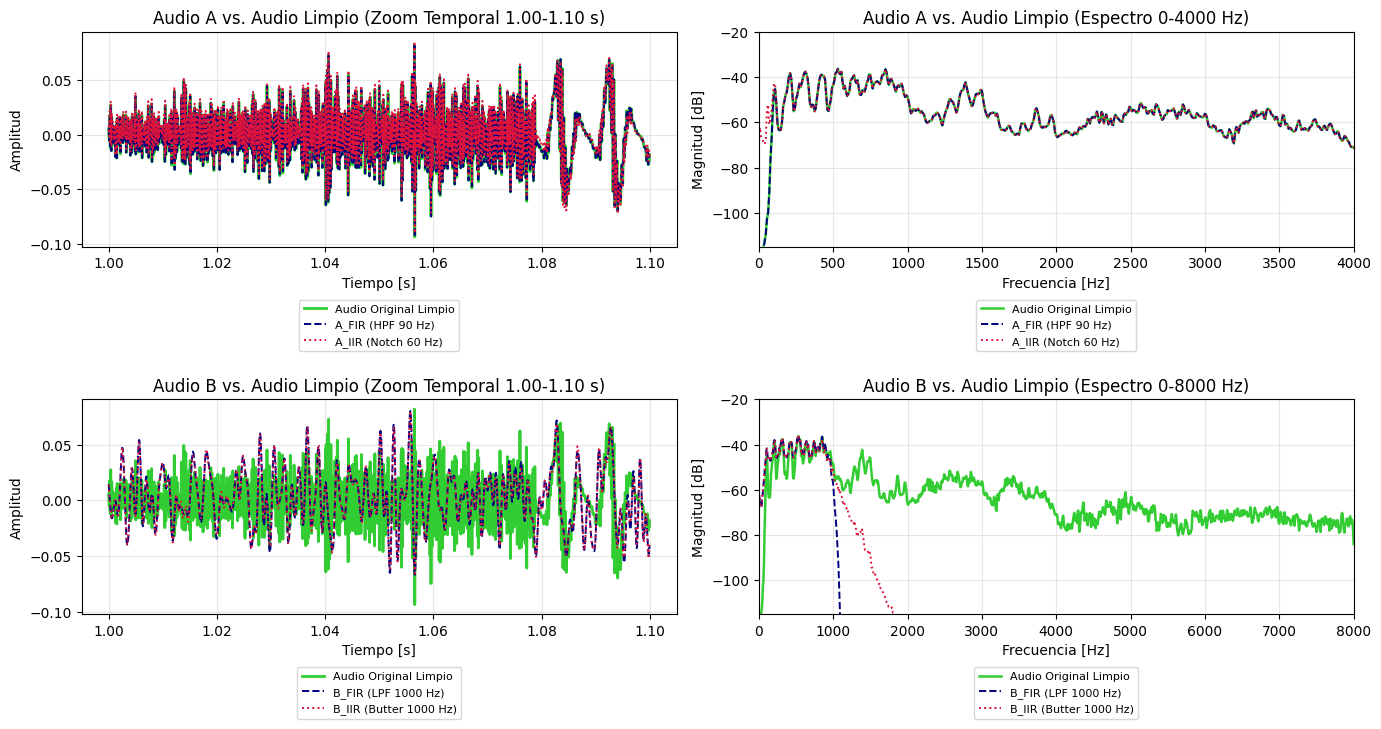

In [ ]:
ARCHIVO_AUDIO_LIMPIO = "A_FIR.wav"

def evaluar_contra_audio_limpio(nombre_archivo):
    nombre_archivo = (nombre_archivo or "").strip()
    if not nombre_archivo:
        print("[APARTADO LISTO PARA USAR] La variable ARCHIVO_AUDIO_LIMPIO está vacía ('').")
        return

    # Buscar el archivo en posibles ubicaciones
    candidatos = [
        nombre_archivo,
        os.path.join(INPUT_DIR, nombre_archivo),
        os.path.join(".", nombre_archivo),
    ]
    ruta_limpio = next((p for p in candidatos if os.path.isfile(p)), None)

    if ruta_limpio is None:
        print(f"⚠️ No se encontró el archivo '{nombre_archivo}'.")
        print(f"   Verifica que el nombre esté bien escrito y que el archivo se encuentre en: {os.path.abspath(INPUT_DIR)}")
        return

    # Usamos cargar_y_muestrear_wav que ya está definida y probada en el notebook
    fs_ref, s_ref, t_ref = cargar_y_muestrear_wav(ruta_limpio)
    if fs_ref != FS:
        num_samples = int(round(len(s_ref) * float(FS) / float(fs_ref)))
        s_ref = sig.resample(s_ref, num_samples)
        fs_ref = FS

    L = min(len(s_ref), len(x_a), len(x_b))
    s_ref = s_ref[:L]
    t_ref = np.arange(L) / FS
    f_ref, _, db_ref, _ = calcular_espectros_segmentados(s_ref, FS, N=2048, ventana="hann")

    print(f"Audio original limpio cargado: {os.path.abspath(ruta_limpio)} ({L} muestras, {FS} Hz)")
    print("Reproductor - Audio Original Limpio (Referencia s[n]):")
    display(Audio(s_ref, rate=FS))

    # Funciones de similitud respecto al audio limpio s_ref
    def metricas_contra_referencia(y_sig):
        y_c = y_sig[:L]
        err = y_c - s_ref
        snr_real = 10.0 * np.log10((np.sum(s_ref**2) + 1e-15) / (np.sum(err**2) + 1e-15))
        rmse = float(np.sqrt(np.mean(err**2)))
        sim_cos = float(np.sum(s_ref * y_c) / (np.sqrt(np.sum(s_ref**2) * np.sum(y_c**2)) + 1e-15)) * 100.0
        _, _, db_y, _ = calcular_espectros_segmentados(y_c, FS, N=2048, ventana="hann")
        err_esp_db = float(np.mean(np.abs(db_y - db_ref)))
        return snr_real, rmse, sim_cos, err_esp_db, db_y

    casos = [
        ("Audio A Contaminado (60 Hz)", x_a),
        ("A_FIR.wav (HPF 90 Hz, N=801)", res_a_fir_z["y"]),
        ("A_IIR.wav (Notch 60 Hz, Q=30)", res_a_iir_z["y"]),
        ("Audio B Contaminado (Fuente)", x_b),
        ("B_FIR.wav (LPF 1000 Hz, N=251)", res_b_fir_z["y"]),
        ("B_IIR.wav (Butter 1000 Hz, o6)", res_b_iir_z["y"]),
    ]

    resultados_ref = {}
    snr_base_a = metricas_contra_referencia(x_a)[0]
    snr_base_b = metricas_contra_referencia(x_b)[0]

    print("\n=== TABLA DE SIMILITUD CONTRA EL AUDIO ORIGINAL LIMPIO ===")
    print(f"{'Señal Comparada':<32} | {'SNR Real':>10} | {'ΔSNR':>10} | {'RMSE':>9} | {'Similitud':>10} | {'Dif. Espectral':>14}")
    print("-" * 98)
    for nombre_c, arr_c in casos:
        snr_v, rmse_v, sim_v, esp_v, db_c = metricas_contra_referencia(arr_c)
        resultados_ref[nombre_c] = (snr_v, rmse_v, sim_v, esp_v, db_c, arr_c[:L])
        base = snr_base_a if "A" in nombre_c.split("_")[0] or "Audio A" in nombre_c else snr_base_b
        d_snr = snr_v - base
        print(f"{nombre_c:<32} | {snr_v:7.2f} dB | {d_snr:+7.2f} dB | {rmse_v:9.5f} | {sim_v:8.2f} % | {esp_v:11.2f} dB")

    # Gráficas comparativas: Audio Original Limpio vs Señales Filtradas (Tiempo y Espectro)
    fig, axes = plt.subplots(2, 2, figsize=(14, 7.5))
    z_idx = slice(16000, 17600)  # zoom temporal de 100 ms (1.00 s a 1.10 s)

    axes[0, 0].plot(t_ref[z_idx], s_ref[z_idx], label="Audio Original Limpio", color="limegreen", lw=2.0)
    axes[0, 0].plot(t_ref[z_idx], res_a_fir_z["y"][z_idx], label="A_FIR (HPF 90 Hz)", color="navy", ls="--", lw=1.4)
    axes[0, 0].plot(t_ref[z_idx], res_a_iir_z["y"][z_idx], label="A_IIR (Notch 60 Hz)", color="crimson", ls=":", lw=1.4)
    axes[0, 0].set_title("Audio A vs. Audio Limpio (Zoom Temporal 1.00-1.10 s)")
    axes[0, 0].set_xlabel("Tiempo [s]"); axes[0, 0].set_ylabel("Amplitud")
    axes[0, 0].legend(bbox_to_anchor=(0.5, -0.22), loc="upper center", fontsize=8)

    axes[0, 1].plot(f_ref, db_ref, label="Audio Original Limpio", color="limegreen", lw=1.8)
    axes[0, 1].plot(f_ref, resultados_ref["A_FIR.wav (HPF 90 Hz, N=801)"][4], label="A_FIR (HPF 90 Hz)", color="navy", ls="--", lw=1.4)
    axes[0, 1].plot(f_ref, resultados_ref["A_IIR.wav (Notch 60 Hz, Q=30)"][4], label="A_IIR (Notch 60 Hz)", color="crimson", ls=":", lw=1.4)
    axes[0, 1].set_xlim(0, 4000); axes[0, 1].set_ylim(-115, -20)
    axes[0, 1].set_title("Audio A vs. Audio Limpio (Espectro 0-4000 Hz)")
    axes[0, 1].set_xlabel("Frecuencia [Hz]"); axes[0, 1].set_ylabel("Magnitud [dB]")
    axes[0, 1].legend(bbox_to_anchor=(0.5, -0.22), loc="upper center", fontsize=8)

    axes[1, 0].plot(t_ref[z_idx], s_ref[z_idx], label="Audio Original Limpio", color="limegreen", lw=2.0)
    axes[1, 0].plot(t_ref[z_idx], res_b_fir_z["y"][z_idx], label="B_FIR (LPF 1000 Hz)", color="navy", ls="--", lw=1.4)
    axes[1, 0].plot(t_ref[z_idx], res_b_iir_z["y"][z_idx], label="B_IIR (Butter 1000 Hz)", color="crimson", ls=":", lw=1.4)
    axes[1, 0].set_title("Audio B vs. Audio Limpio (Zoom Temporal 1.00-1.10 s)")
    axes[1, 0].set_xlabel("Tiempo [s]"); axes[1, 0].set_ylabel("Amplitud")
    axes[1, 0].legend(bbox_to_anchor=(0.5, -0.22), loc="upper center", fontsize=8)

    axes[1, 1].plot(f_ref, db_ref, label="Audio Original Limpio", color="limegreen", lw=1.8)
    axes[1, 1].plot(f_ref, resultados_ref["B_FIR.wav (LPF 1000 Hz, N=251)"][4], label="B_FIR (LPF 1000 Hz)", color="navy", ls="--", lw=1.4)
    axes[1, 1].plot(f_ref, resultados_ref["B_IIR.wav (Butter 1000 Hz, o6)"][4], label="B_IIR (Butter 1000 Hz)", color="crimson", ls=":", lw=1.4)
    axes[1, 1].set_xlim(0, 8000); axes[1, 1].set_ylim(-115, -20)
    axes[1, 1].set_title("Audio B vs. Audio Limpio (Espectro 0-8000 Hz)")
    axes[1, 1].set_xlabel("Frecuencia [Hz]"); axes[1, 1].set_ylabel("Magnitud [dB]")
    axes[1, 1].legend(bbox_to_anchor=(0.5, -0.22), loc="upper center", fontsize=8)

    plt.tight_layout()
    plt.show()

evaluar_contra_audio_limpio(ARCHIVO_AUDIO_LIMPIO)